In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

df = pd.read_csv('student_grade_ses_dataset.csv')

# Provide idea of the dataframe we are dealing with 
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  object 
 1   academic_year               12025 non-null  object 
 2   survey_date                 12025 non-null  object 
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  object 
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  object 
 7   residence_type              12025 non-null  object 
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  object 
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      116

In [2]:
# Data Preprocessing 

# 1. Cleaning Duplicate Rows 
duplicates = df[df.duplicated()]
print("Duplicate Rows:")
print(duplicates)

row_count_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
row_count_after = len(df)
print(f"{row_count_before} rows -> {row_count_after} after removing duplicates")

# 2. Set 'student_id' as the index and drop it from the standard columns
is_all_unique = df['student_id'].is_unique
print(f"Column student_id uniqueness: {is_all_unique}")
df = df.set_index('student_id', drop=True)


Duplicate Rows:
      student_id academic_year survey_date  age  gender  grade_level  \
2052   STU100247     2024-2025     10/3/25   13    Male            8   
2323   STU111139     2023-2024      5/3/25   17  Female           12   
4406   STU107482     2022-2023      1/5/25   14   Other            9   
5645   STU110619     2023-2024      8/5/25   11    Male            7   
5715   STU104160     2022-2023     12/5/25   13  Female            8   
5801   STU108370     2022-2023     22/3/25   18    Male           12   
6089   STU100191     2022-2023      8/3/25   15  Female           10   
6099   STU108270     2021-2022     16/4/25   12    Male            8   
7395   STU111279     2024-2025     19/4/25   15  Female            9   
7700   STU101857     2021-2022     10/5/25   14  Female           10   
7788   STU108388     2021-2022     10/4/25   18  Female           12   
7902   STU104036     2022-2023      3/4/25   14  Female           10   
7990   STU105705     2023-2024      7/3/25   15 

## TODO: What to do about missing rows  

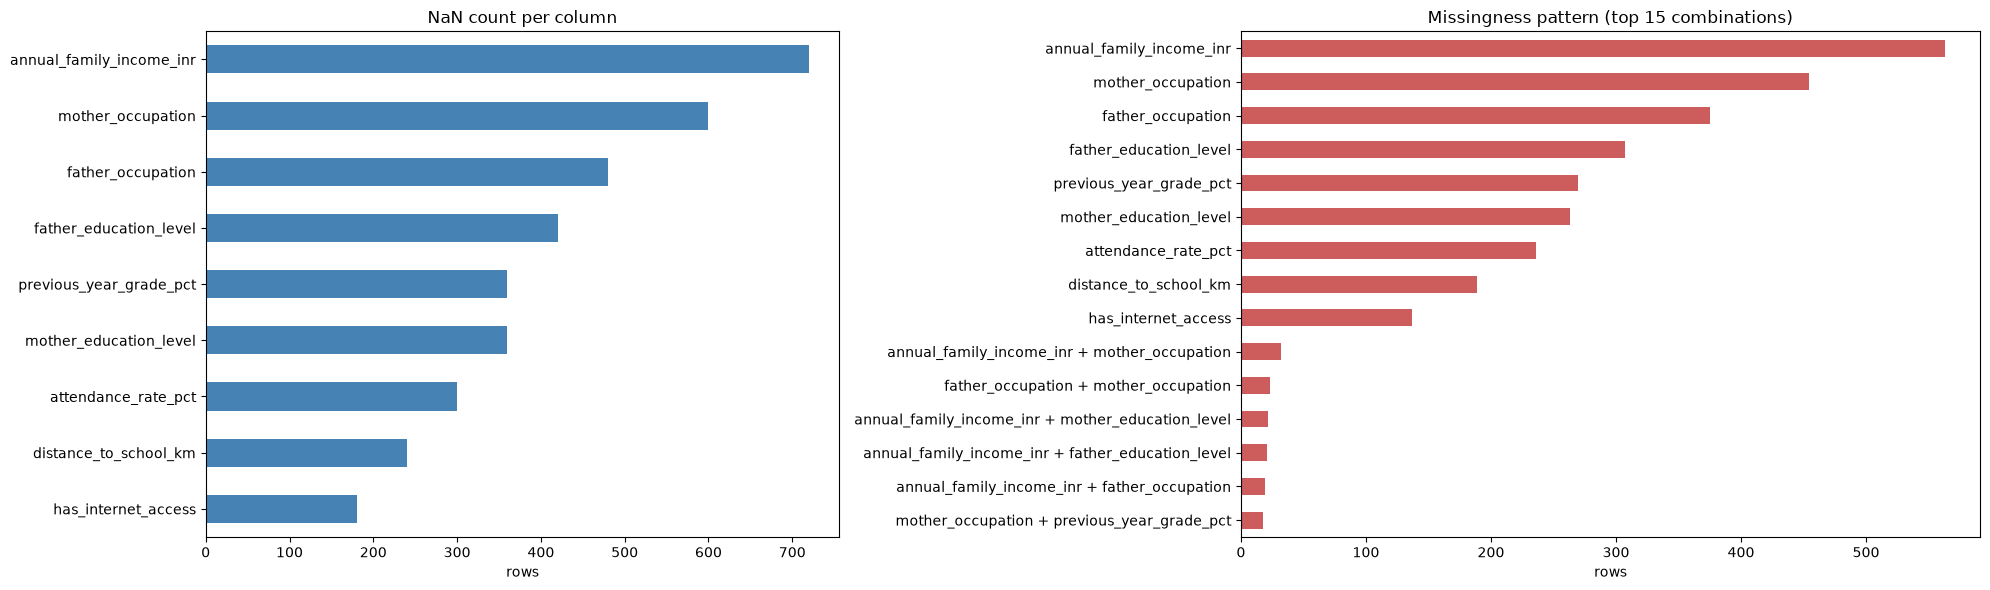

annual_family_income_inr                             563
mother_occupation                                    454
father_occupation                                    375
father_education_level                               307
previous_year_grade_pct                              270
mother_education_level                               263
attendance_rate_pct                                  236
distance_to_school_km                                189
has_internet_access                                  137
annual_family_income_inr + mother_occupation          32
father_occupation + mother_occupation                 23
annual_family_income_inr + mother_education_level     22
annual_family_income_inr + father_education_level     21
annual_family_income_inr + father_occupation          19
mother_occupation + previous_year_grade_pct           18
Name: count, dtype: int64


In [3]:
import matplotlib.pyplot as plt

na = df.isna()
cols = na.columns[na.any()]
na = na[cols]

fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={'width_ratios': [1.2, 1.4]})

# 1. NaN count per column
na.sum().sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('NaN count per column')
axes[0].set_xlabel('rows')

# 2. Missingness pattern: which combinations of columns are missing together
pattern = na[na.any(axis=1)].apply(lambda r: ' + '.join(r.index[r]), axis=1).value_counts()
pattern.head(15).sort_values().plot.barh(ax=axes[1], color='indianred')
axes[1].set_title('Missingness pattern (top 15 combinations)')
axes[1].set_xlabel('rows')

plt.tight_layout()
plt.show()

print(pattern.head(15))

In [4]:
# Check for missing values 
missing_rows = df[df.isna().any(axis=1)]
print("Rows with missing values:")
print(missing_rows) 

# Calculate percentage of missing cells per column 
col_missing_pct = df.isna().mean() * 100

# Filter to only show columns that actually have missing data, sorted highest to lowest
print("\nPercentage of missing values per column:")
print(col_missing_pct[col_missing_pct > 0].sort_values(ascending=False))

# TEMPORARY: drop rows with missing values until a proper imputation strategy is added
rows_before = len(df)
df = df.dropna()
print(f"\n{rows_before} rows -> {len(df)} after dropping rows with missing values")

Rows with missing values:
           academic_year survey_date  age  gender  grade_level  \
student_id                                                       
STU107546      2022-2023      2/5/25   15    Male           10   
STU106506      2022-2023      7/4/25   18    Male           12   
STU103794      2023-2024     20/3/25   16  Female           12   
STU101647      2022-2023     13/3/25   14    Male           10   
STU105006      2021-2022      8/4/25   15    Male            9   
...                  ...         ...  ...     ...          ...   
STU108600      2024-2025      7/3/25   17    Male           11   
STU108332      2024-2025     19/4/25   16  Female           10   
STU106690      2024-2025      6/3/25   13  Female            9   
STU108524      2021-2022      8/4/25   13  Female            9   
STU110137      2023-2024     17/4/25   12  Female            7   

                 school_type residence_type  family_size  num_siblings  \
student_id                               

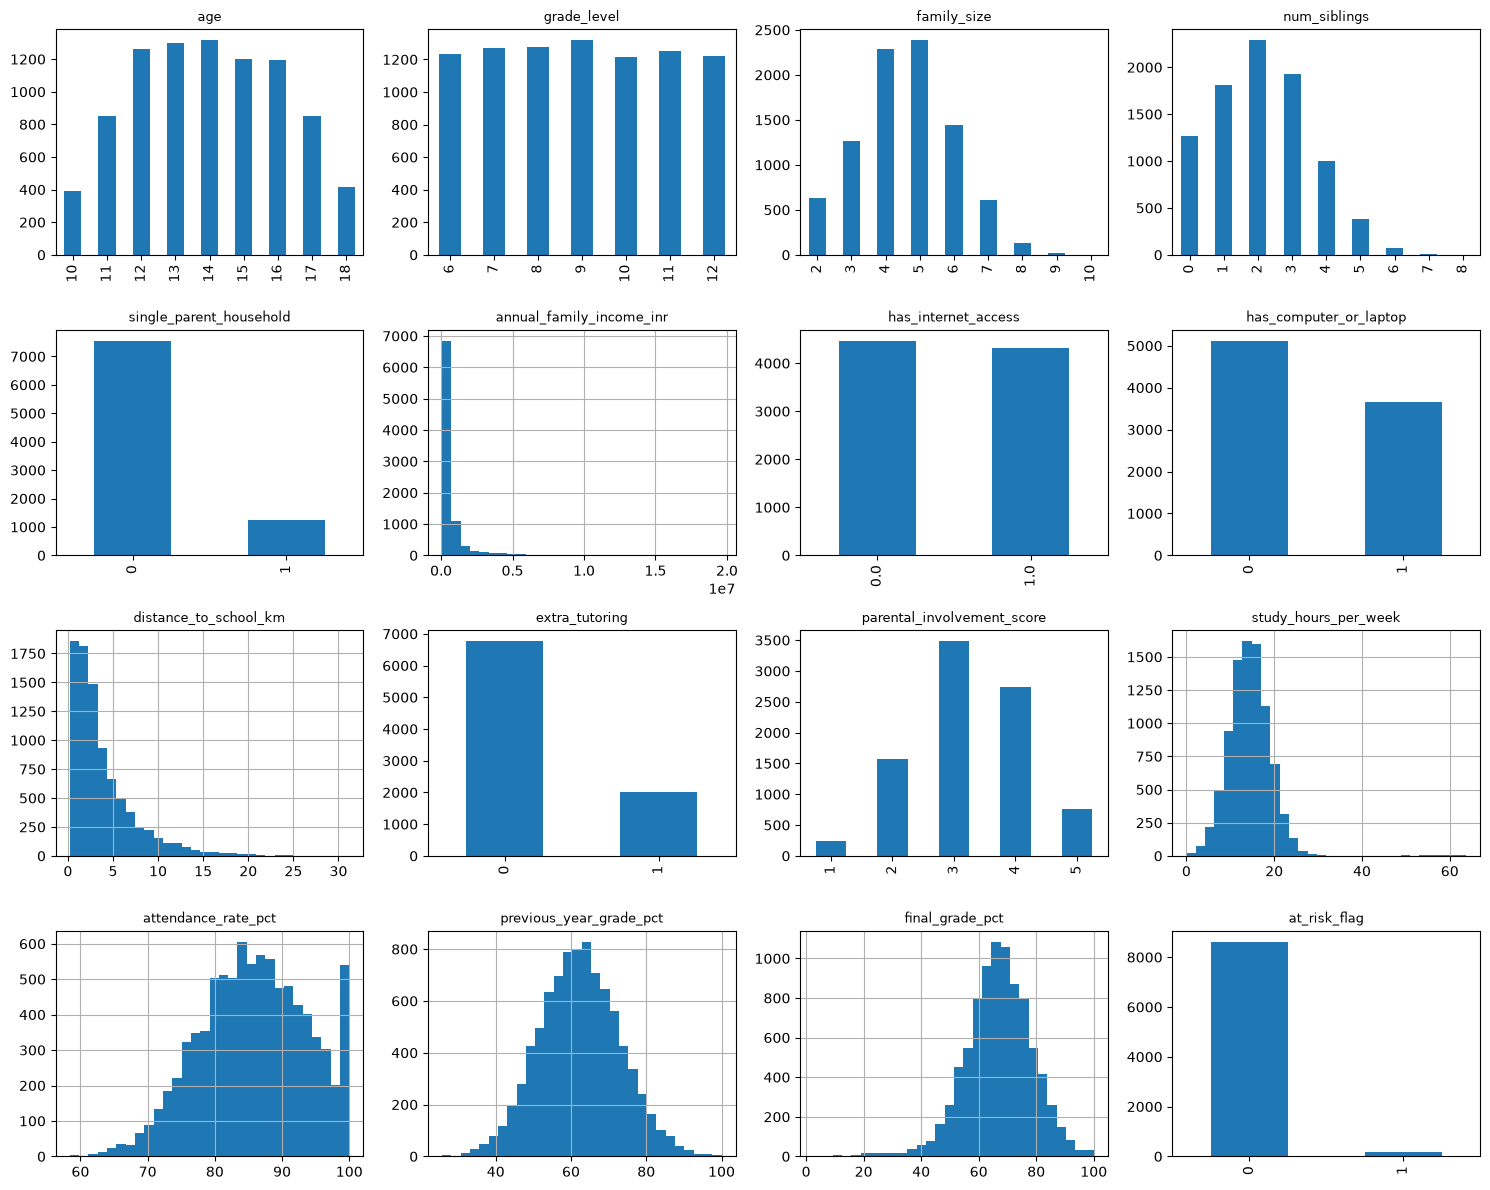

In [5]:
# Visualisation of predictors 

# Columns with only a few integer values get one bar per value
# Default histogram bins cut across the integers and leave gaps
num_cols = df.select_dtypes('number').columns

fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    if df[col].nunique() <= 10:
        df[col].value_counts().sort_index().plot(kind='bar', ax=ax)
        ax.set_xlabel('')
    else:
        df[col].hist(bins=30, ax=ax)
    ax.set_title(col, fontsize=9)

plt.tight_layout()
plt.show()

## Skewed income column: annual_family_income_inr

From the histogram above, we can see that the annual_family_income_inr column is very right-skewed. In the data it ranges from about ₹60,000 to ₹19.6 million, a factor of more than 300. Most families sit near the low end and a few earn far more. On the raw scale, the few very rich families stretch the axis. This creates the problems of the ultra-wealthy outliers having too much influence in linear models. 

In such cases, a log transformation is ideal because algorithms like linear regression, logistics regression, K-means clustering and PCA are highly sensitive to extreme values and perform better when features are normally distributed. As the log is a monotonically increasing function, it naturally squashes massive numbers closer together while preserving the exact rank order of data.

In [6]:
# From the histogram above, heavily skewed income, so log-transform 
print(f"annual_family_income_inr skew: {df['annual_family_income_inr'].skew()}")
df['log_income'] = np.log(df.pop('annual_family_income_inr'))
print(f"log_income skew: {df['log_income'].skew()}")

annual_family_income_inr skew: 4.780808241327416
log_income skew: 0.43251024385922143


## Schema Setup

Based off the variable histograms above, we can deduce which of the columns are discrete/continuous/categorical and we can form the column schema below. 

In [7]:
# Schema Setup 

REGRESSION_TARGET     = 'final_grade_pct'
CLASSIFICATION_TARGET = 'grade_class'

CONTINUOUS_COLS = [
    'distance_to_school_km', 
    'study_hours_per_week', 
    'attendance_rate_pct',          
    'previous_year_grade_pct', 
    'log_income'
]

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = [
    'age', 
    'grade_level', 
    'family_size', 
    'num_siblings', 
    'single_parent_household',
    'has_internet_access', 
    'has_computer_or_laptop', 
    'extra_tutoring',
    'parental_involvement_score'
]

# Text labels
CATEGORICAL_COLS = [
    'academic_year', 
    'gender', 
    'school_type', 
    'residence_type', 
    'family_income_bracket',
    'father_education_level', 
    'mother_education_level', 
    'father_occupation',
    'mother_occupation', 
    'scholarship_status'
]

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [8]:
X = df[PREDICTOR_COLS]
print('X:', X.shape)

X: (8785, 24)


## Highly Correlated Predictors 



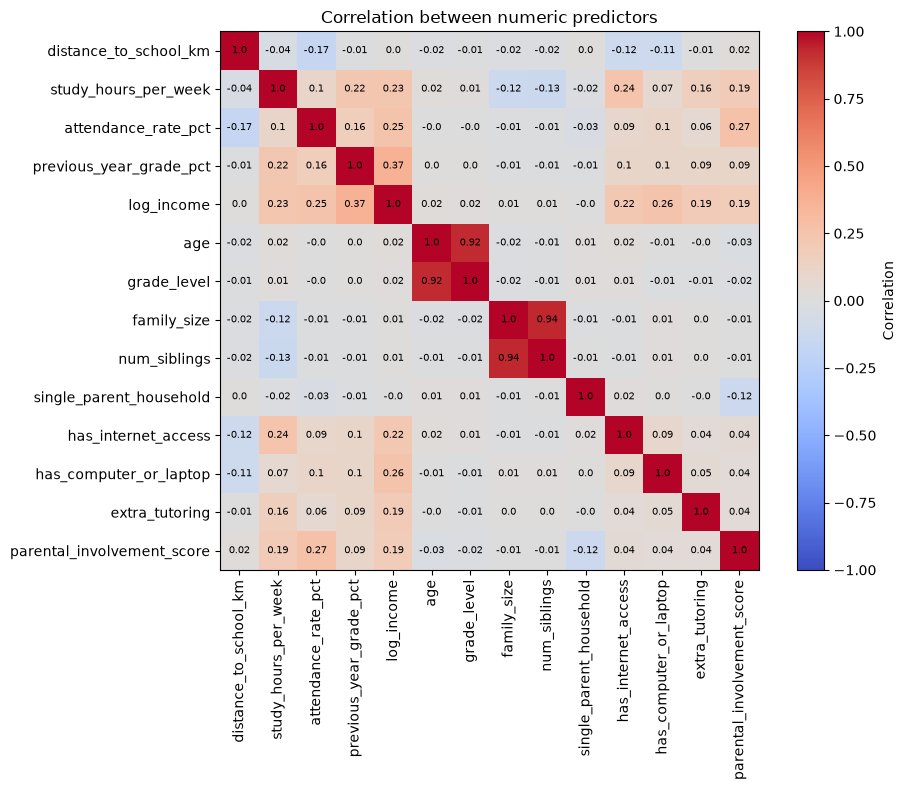

In [9]:
# Correlation heatmap of the numeric predictors
# (categorical columns are text, so they are left out here)
corr = X[NUMERIC_COLS].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

# write the correlation value in each square
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=7)

plt.title('Correlation between numeric predictors')
plt.tight_layout()
plt.show()

From the heatmap, most predictors are only weakly correlated with each other. Two pairs stand out:

- `age` and `grade_level` (r = 0.93): students in the same grade are mostly the same age.
- `family_size` and `num_siblings` (r = 0.94): more siblings means a bigger family.

Keeping both columns of a pair gives the linear models the same information twice, which makes the OLS coefficients unstable. So we drop one column from each pair:

- Keep `grade_level`, drop `age`. Grade level tells us which curriculum the student is in, and age within a grade adds little.
- Keep `family_size`, drop `num_siblings`. Family size also counts parents and other relatives, so it is the more general measure.

Both columns in each pair are almost uncorrelated with `final_grade_pct` (|r| about 0.00 for age/grade level and 0.05 for family size/siblings), so the choice is made on what the variable means rather than on the target. This also avoids using the target before the train/test split.

In [10]:
# Drop one predictor from each highly correlated pair
# age vs grade_level (r = 0.93) -> keep grade_level
# family_size vs num_siblings (r = 0.94) -> keep family_size
DROP_COLS = ['age', 'num_siblings']

DISCRETE_COLS = [c for c in DISCRETE_COLS if c not in DROP_COLS]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

X                = df[PREDICTOR_COLS]         # Shared predictors
Y_regression     = df[REGRESSION_TARGET]      # Numeric final grade
Y_classification = df[CLASSIFICATION_TARGET]  # Grade band
print('Dropped:', DROP_COLS)
print('X:', X.shape)

Dropped: ['age', 'num_siblings']
X: (8785, 22)


In [11]:
# Setup helper functions for data preparation so that X-train and X-test can be massaged into a format palatable to each model 

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import BaseEstimator, RegressorMixin
from pygam import LinearGAM, s, l      # pip install pygam
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
from scipy.stats import norm

# Columns with no natural order: one-hot encoded
ONEHOT_COLUMNS = ['gender', 'school_type', 'residence_type', 'academic_year',
                  'father_occupation', 'mother_occupation']

# Columns with a clear order (lowest level first): ordinal encoded
ORDINAL_COLUMNS = {
    'father_education_level': [
        'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
        "Bachelor's Degree", "Master's Degree", 'Doctorate',
    ],
    'mother_education_level': [
        'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
        "Bachelor's Degree", "Master's Degree", 'Doctorate',
    ],
    'family_income_bracket': ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High'],
    'scholarship_status': ['No Scholarship', 'Partial', 'Full'],
}

def build_prep(scale):
    # one-hot and ordinal encoders are the same for every family. Only scaling differs
    return ColumnTransformer([
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ONEHOT_COLUMNS),
        ('ordinal', OrdinalEncoder(categories=list(ORDINAL_COLUMNS.values())), list(ORDINAL_COLUMNS)),
        ('num', StandardScaler() if scale else 'passthrough', NUMERIC_COLS),
    ])

def make_linear_prep():  # OLS, Ridge, Lasso
    return build_prep(scale=True)

def make_gam_prep():     # GAM: splines handle the shape, so no scaling
    return build_prep(scale=False)

class GAMRegressor(BaseEstimator, RegressorMixin):
    # Wrapper so pygam's LinearGAM works inside a Pipeline and GridSearchCV
    # Smooth spline term for each continuous column, linear term for every other column
    def __init__(self, n_splines=10, lam=0.6):
        self.n_splines = n_splines
        self.lam = lam      # smoothing penalty, bigger = smoother curves

    def fit(self, X, y):
        first_continuous = X.shape[1] - len(NUMERIC_COLS)   # one-hot and ordinal columns come first
        last_continuous = first_continuous + len(CONTINUOUS_COLS)
        terms = l(0)
        for j in range(1, X.shape[1]):
            if first_continuous <= j < last_continuous:
                terms = terms + s(j, n_splines=self.n_splines, lam=self.lam)
            else:
                terms = terms + l(j)
        self.gam_ = LinearGAM(terms).fit(X, y)
        return self

    def predict(self, X):
        return self.gam_.predict(X)

def make_knn_prep():     # KNN: distances need scaled columns
    return build_prep(scale=True)

def make_tree_prep():    # decision tree, random forest
    return build_prep(scale=False)

def make_gbt_prep():     # gradient boosting
    return build_prep(scale=False)

def make_svr_prep():     # SVM: RBF kernel uses distances, so scale
    return build_prep(scale=True)

def compute_test_metrics(fitted_model, X_train, Y_train, X_test, Y_test):
    # Returns (RMSE, MAE, R2, CV RMSE, mean Gaussian log-likelihood) of a fitted model on the test set
    test_predictions = fitted_model.predict(X_test)
    # CV RMSE on the training data: from the grid search if tuned, otherwise 5-fold cross_val_score
    if hasattr(fitted_model, 'best_score_'):
        cv_rmse = -fitted_model.best_score_
    else:
        cv_rmse = -cross_val_score(fitted_model, X_train, Y_train, cv=5, scoring='neg_root_mean_squared_error').mean()
    # Likelihood uses the CV RMSE as the noise sd, so the test set is not used to choose it
    return (root_mean_squared_error(Y_test, test_predictions),
            mean_absolute_error(Y_test, test_predictions),
            r2_score(Y_test, test_predictions),
            cv_rmse,
            norm.logpdf(Y_test, loc=test_predictions, scale=cv_rmse).mean())



# Baseline versus square-root-transformed regression

This notebook compares all nine regressors on identical 85/15 splits (seeds 0–19), without oversampling. Classification is omitted. Use the **ST5227 Project (Python 3.11)** kernel from this directory.

Transform grades with `sqrt(grade)` and invert predictions using `maximum(z, 0) ** 2`. Zero and 100 require no offset. Negative transformed predictions map to zero rather than being reflected by squaring. Predictions are not capped at 100. No retransformation bias correction is applied: squaring a conditional mean on the transformed scale need not recover the conditional mean grade. A transformation changes the fitting objective; improved accuracy is an empirical question. CV selection and all test metrics use original grade points.

Both conditions use the same fixed compact parameter grids, training-only searches and matching validation folds as the logit experiment. Four split workers run in parallel; inner searches, forests and numerical libraries use one thread. Completed splits are checkpointed under `sqrt-results/` with a data/configuration fingerprint.

Execute or resume using `python run_sqrt_notebook.py` after activating `st5227-project`. Use `--smoke` for a separate two-split, 240-student check.

Inspect transformations without fitting models in `Target-Grade-Distributions.ipynb`. The shared plotting registry in `target_distributions.py` also drives the distribution plots below.


In [ ]:
from IPython.display import display, Markdown
from scipy.stats import gaussian_kde
from sqrt_experiment import grade_to_sqrt, sqrt_to_grade

raw_grades = pd.read_csv('student_grade_ses_dataset.csv')[REGRESSION_TARGET]
display(pd.DataFrame({'raw data': [len(raw_grades), raw_grades.eq(0).sum(), raw_grades.eq(100).sum(), raw_grades.isna().sum()],
                      'analysis data': [len(Y_regression), Y_regression.eq(0).sum(), Y_regression.eq(100).sum(), Y_regression.isna().sum()]},
                     index=['Students', 'Exactly 0', 'Exactly 100', 'Missing']))
band_order = ['A','B','C','D','F']
band_counts = df[CLASSIFICATION_TARGET].value_counts().reindex(band_order, fill_value=0)
display(pd.DataFrame({'students':band_counts, 'percent':100*band_counts/len(df)}).round(2))
display(Markdown(f"Low grades are underrepresented: F accounts for {band_counts['F']/len(df):.1%} of analysis students. This describes the observed distribution, not proof of biased sampling. KDE smoothing may distort density near 0 and 100; the histogram and counts retain the observed support."))
assert np.allclose(sqrt_to_grade(grade_to_sqrt(np.array([0.,2.8,50.,100.]))), [0.,2.8,50.,100.])
assert np.array_equal(sqrt_to_grade(np.array([-2., 0., 10., 11.])), [0., 0., 100., 121.])
# Shared registry: add or remove modes here without changing the plotting code.
from target_distributions import TARGET_MODES, plot_target_distributions
modes = TARGET_MODES.copy()
# modes['Cube root'] = dict(transform=np.cbrt, xlabel='Cube root of grade', support=(0, np.cbrt(100)))
display(plot_target_distributions(Y_regression, modes=modes).round(3))


In [13]:
import time, platform, importlib.metadata, json
from sqrt_experiment import run_experiments, NAMES, CONDITIONS, GRIDS
REGRESSION_NAMES = NAMES
NUMBER_OF_EXPERIMENTS = 20
N_JOBS = 4
schema = {key: globals()[key] for key in ['CONTINUOUS_COLS','NUMERIC_COLS','PREDICTOR_COLS','ONEHOT_COLUMNS','ORDINAL_COLUMNS']}
start = time.perf_counter()
results, result_directory = run_experiments(X, Y_regression, df[CLASSIFICATION_TARGET], schema,
                                          n_splits=NUMBER_OF_EXPERIMENTS, n_jobs=N_JOBS)
elapsed_seconds = time.perf_counter() - start
regression_predictions = pd.concat([p for r in results for p in r['predictions']], ignore_index=True)
regression_metrics = pd.DataFrame([p for r in results for p in r['metrics']])
regression_timings = pd.DataFrame([p for r in results for p in r['timings']])
for label, frame in [('predictions',regression_predictions),('metrics',regression_metrics),('timings',regression_timings)]:
    frame.to_csv(result_directory / (label+'.csv'),index=False)
versions = {p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','pygam','joblib']}
manifest = dict(python=platform.python_version(),versions=versions,splits=NUMBER_OF_EXPERIMENTS,workers=N_JOBS,
                elapsed_seconds=elapsed_seconds, grids=GRIDS, transform='sqrt(y)', inverse='maximum(z, 0) ** 2', upper_clip=False, test_size=.15)
(result_directory/'manifest.json').write_text(json.dumps(manifest,indent=2))
print(f'Completed {len(results)} paired splits in {elapsed_seconds/60:.1f} minutes. Results: {result_directory}')
display(manifest)

Split 1: Baseline complete


Split 4: Baseline complete


Split 3: Baseline complete
Split 2: Baseline complete


Split 1: Sqrt complete


Split 4: Sqrt complete


Split 2: Sqrt complete


... (31 outputs left out)

Split 19: Sqrt complete


Split 20: Sqrt complete


Completed 20 paired splits in 12.6 minutes. Results: sqrt-results/cf0a39a78229dfde


{'python': '3.11.18',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'pygam': '0.11.0',
  'joblib': '1.6.0'},
 'splits': 20,
 'workers': 4,
 'elapsed_seconds': 755.9180448750267,
 'grids': {'Ridge': {'model__alpha': [0.1, 1, 10, 100]},
  'Lasso': {'model__alpha': [0.001, 0.01, 0.1]},
  'GAM': {'model__lam': [0.1, 1, 10, 100]},
  'k-NN': {'model__n_neighbors': [5, 25, 100]},
  'DT': {'model__max_depth': [3, 6, None], 'model__min_samples_leaf': [5, 20]},
  'RF': {'model__max_features': [0.5, 1.0],
   'model__min_samples_leaf': [5, 20]},
  'GBT': {'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 6]}},
 'transform': 'sqrt(y)',
 'inverse': 'maximum(z, 0) ** 2',
 'upper_clip': False,
 'test_size': 0.15}

## Paired comparison on original grade points

Differences below are sqrt minus baseline: negative error differences favor sqrt. Bars across splits show variation, not independent-sample confidence intervals. Repeated test sets overlap. F-band signed error is predicted minus actual, so positive values indicate overprediction.

RMSE           MAE            R2          F MAE         \
                   mean    std   mean    std   mean    std    mean    std   
model condition                                                             
DT    Baseline   10.013  0.308  7.449  0.188  0.259  0.026  36.151  2.622   
      Sqrt       10.039  0.306  7.468  0.178  0.255  0.024  35.917  2.514   
GAM   Baseline    9.539  0.352  7.000  0.186  0.327  0.030  35.817  2.681   
      Sqrt        9.554  0.343  7.037  0.182  0.325  0.029  35.447  2.651   
GBT   Baseline    9.628  0.344  7.086  0.188  0.315  0.029  36.078  2.651   
      Sqrt        9.650  0.334  7.126  0.182  0.311  0.028  35.698  2.656   
Lasso Baseline    9.529  0.349  6.995  0.184  0.329  0.029  35.884  2.688   
      Sqrt        9.542  0.344  7.027  0.177  0.327  0.029  35.545  2.658   
Naive Baseline   11.635  0.243  8.932  0.183 -0.001  0.001  37.739  1.698   
      Sqrt       11.649  0.231  8.961  0.175 -0.003  0.003  37.171  1.700   
OLS   Baseline    9.533  0.349  7.000  0.182  0.328  0.030  35.822  2.703   
      Sqrt        9.548  0.342  7.034  0.178  0.326  0.029  35.509  2.645   
RF    Baseline    9.695  0.332  7.144  0.183  0.305  0.028  36.121  2.641   
      Sqrt        9.711  0.318  7.182  0.177  0.303  0.026  35.693  2.585   
Ridge Baseline    9.531  0.349  6.998  0.181  0.328  0.029  35.849  2.697   
      Sqrt        9.545  0.342  7.032  0.177  0.326  0.029  35.536  2.640   
k-NN  Baseline    9.991  0.304  7.458  0.180  0.262  0.021  36.320  2.317   
      Sqrt       10.038  0.293  7.518  0.173  0.255  0.020  35.880  2.314   

                F overprediction         
                            mean    std  
model condition                          
DT    Baseline            36.151  2.622  
      Sqrt                35.917  2.514  
GAM   Baseline            35.817  2.681  
      Sqrt                35.447  2.651  
GBT   Baseline            36.078  2.651  
      Sqrt                35.698  2.656  
Lasso Baseline            35.884  2.688  
      Sqrt                35.545  2.658  
Naive Baseline            37.739  1.698  
      Sqrt                37.171  1.700  
OLS   Baseline            35.822  2.703  
      Sqrt                35.509  2.645  
RF    Baseline            36.121  2.641  
      Sqrt                35.693  2.585  
Ridge Baseline            35.849  2.697  
      Sqrt                35.536  2.640  
k-NN  Baseline            36.320  2.317  
      Sqrt                35.880  2.314

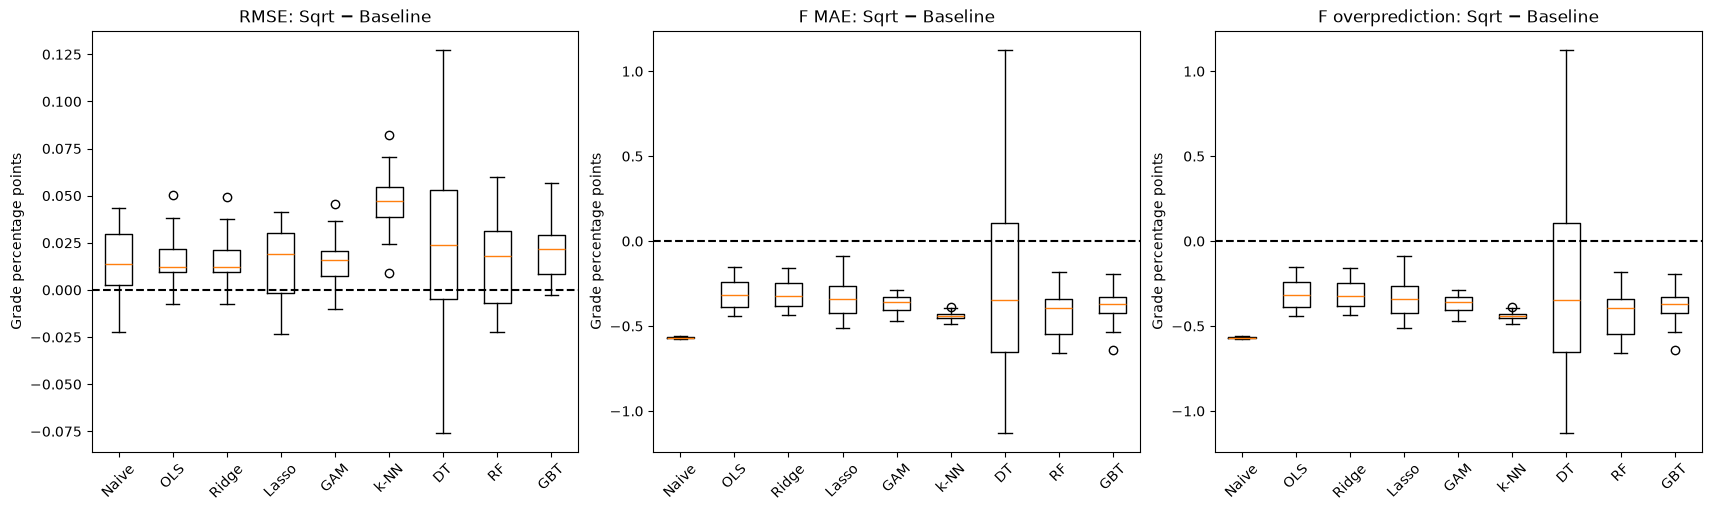

**Observed tradeoff.** OLS: mean RMSE change +0.02, F-band MAE change -0.31 points; RF: mean RMSE change +0.02, F-band MAE change -0.43 points. These are exploratory comparisons across overlapping test splits.

In [14]:
all_predictions = regression_predictions.copy()
all_metrics = regression_metrics.copy()
all_timings = regression_timings.copy()
all_predictions['absolute error'] = (all_predictions.predicted-all_predictions.actual).abs()
all_predictions['overprediction'] = all_predictions.predicted-all_predictions.actual
f_metrics = (all_predictions[all_predictions['grade band'].eq('F')]
    .groupby(['experiment','condition','model']).agg(**{'F MAE':('absolute error','mean'),
          'F overprediction':('overprediction','mean'), 'F support':('actual','size')}).reset_index())
comparison = all_metrics.merge(f_metrics, on=['experiment','condition','model'], how='left')
metrics_to_compare = ['RMSE','MAE','R2','F MAE','F overprediction']
display(comparison.groupby(['model','condition'])[metrics_to_compare].agg(['mean','std']).round(3))
fig, axes = plt.subplots(1,3,figsize=(17,5),layout='constrained')
paired_deltas = {}
for ax, metric in zip(axes,['RMSE','F MAE','F overprediction']):
    pairs = comparison.pivot(index=['experiment','model'],columns='condition',values=metric)
    delta = (pairs['Sqrt']-pairs['Baseline']).unstack('model').reindex(columns=NAMES)
    paired_deltas[metric] = delta
    ax.boxplot([delta[m].dropna() for m in NAMES],tick_labels=NAMES)
    ax.axhline(0,color='black',ls='--'); ax.tick_params(axis='x',rotation=45)
    ax.set(title=metric+': Sqrt − Baseline',ylabel='Grade percentage points')
plt.show()
comparison.to_csv(result_directory/'comparison.csv',index=False)
display(Markdown('**Observed tradeoff.** '+ '; '.join(
    f"{m}: mean RMSE change {paired_deltas['RMSE'][m].mean():+.2f}, F-band MAE change {paired_deltas['F MAE'][m].mean():+.2f} points"
    for m in ['OLS','RF'])+'. These are exploratory comparisons across overlapping test splits.'))
# Check pairing and nonnegative predictions on every model and split.
for (_, _), group in all_predictions.groupby(['experiment','model']):
    a=group[group.condition.eq('Baseline')].set_index('student_id')
    b=group[group.condition.eq('Sqrt')].set_index('student_id')
    assert a.index.equals(b.index) and np.array_equal(a.actual,b.actual)
sqrt_predictions=all_predictions[all_predictions.condition.eq('Sqrt')].predicted
assert np.isfinite(sqrt_predictions).all() and (sqrt_predictions >= 0).all()


In [15]:
# Generate findings from the current run, including smoke runs.
means = comparison.groupby(['model','condition'])[['RMSE','F MAE']].mean()
rmse_delta = paired_deltas['RMSE'].mean()
f_delta = paired_deltas['F MAE'].mean()
lines = [f"### Findings from {NUMBER_OF_EXPERIMENTS} paired splits", "",
         f"Square root reduced mean overall RMSE for {int((rmse_delta < 0).sum())} of {len(NAMES)} models and F-band MAE for {int((f_delta < 0).sum())} of {len(NAMES)} models.", "",
         "| Model | Baseline RMSE | Sqrt RMSE | Baseline F MAE | Sqrt F MAE |",
         "|---|---:|---:|---:|---:|"]
for name in NAMES:
    base, transformed = means.loc[(name,'Baseline')], means.loc[(name,'Sqrt')]
    lines.append(f"| {name} | {base['RMSE']:.3f} | {transformed['RMSE']:.3f} | {base['F MAE']:.3f} | {transformed['F MAE']:.3f} |")
lines += ["", "Errors are grade percentage points. Overlapping splits are exploratory comparisons, not independent replications. Check the size of changes and low-grade overprediction alongside overall accuracy. This baseline uses the same compact grids as the logit experiment and can differ from the original pilot-tuned notebook."]
display(Markdown('\n'.join(lines)))


### Findings from 20 paired splits

Square root reduced mean overall RMSE for 0 of 9 models and F-band MAE for 9 of 9 models.

| Model | Baseline RMSE | Sqrt RMSE | Baseline F MAE | Sqrt F MAE |
|---|---:|---:|---:|---:|
| Naive | 11.635 | 11.649 | 37.739 | 37.171 |
| OLS | 9.533 | 9.548 | 35.822 | 35.509 |
| Ridge | 9.531 | 9.545 | 35.849 | 35.536 |
| Lasso | 9.529 | 9.542 | 35.884 | 35.545 |
| GAM | 9.539 | 9.554 | 35.817 | 35.447 |
| k-NN | 9.991 | 10.038 | 36.320 | 35.880 |
| DT | 10.013 | 10.039 | 36.151 | 35.917 |
| RF | 9.695 | 9.711 | 36.121 | 35.693 |
| GBT | 9.628 | 9.650 | 36.078 | 35.698 |

Errors are grade percentage points. Overlapping splits are exploratory comparisons, not independent replications. Check the size of changes and low-grade overprediction alongside overall accuracy. This baseline uses the same compact grids as the logit experiment and can differ from the original pilot-tuned notebook.

## Baseline: detailed regression diagnostics

All errors and prediction-response curves use original grade points. GAM contributions and Lasso coefficients use grade-point units.

In [16]:
condition = 'Baseline'
regression_prediction_records = [p for r in results for p in r['predictions'] if p['condition'].iloc[0] == condition]
regression_timing_records = [p for r in results for p in r['timings'] if p['condition'] == condition]
model_error_lists = [all_metrics[(all_metrics.condition == condition) & (all_metrics.model == m)].sort_values('experiment')[['RMSE','MAE','R2','CV RMSE','LogLik']].to_numpy() for m in NAMES]
regression_diagnostic_models = {m:results[0]['models'][(condition,m)] for m in NAMES}
regression_diagnostic_data = results[0]['data']
importance_records = [p for r in results for p in r['importance'] if p['condition']==condition]
lasso_selection_records = [{k:v for k,v in p.items() if k not in ['condition','model']} for r in results for p in r['selections'] if p['condition']==condition]


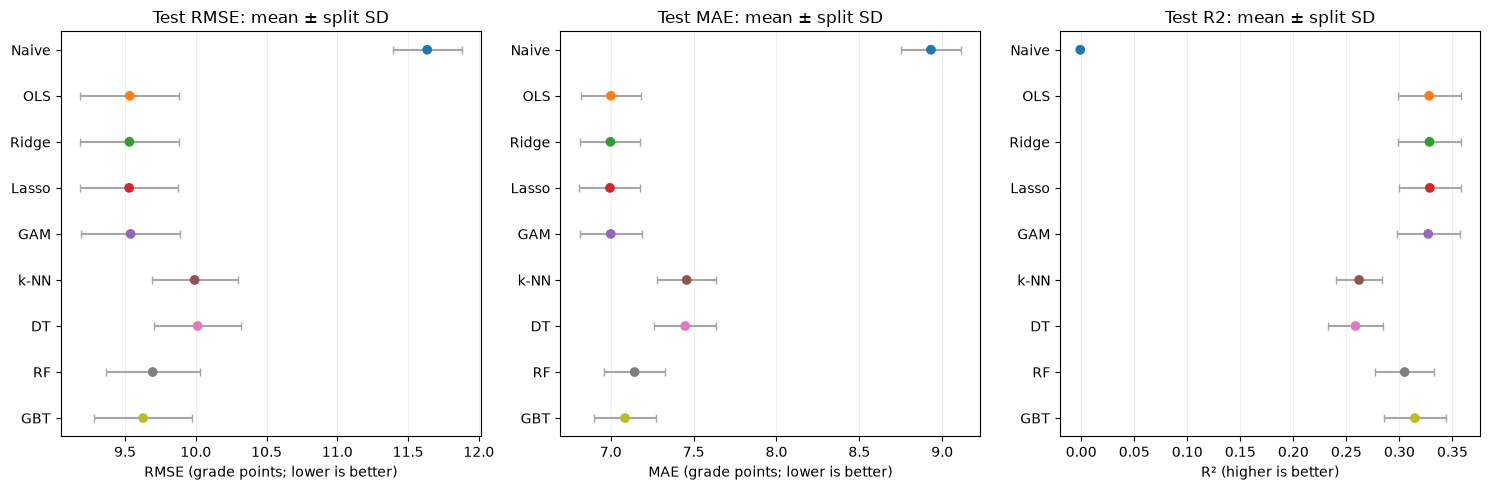

RMSE           MAE            R2       
         mean    std   mean    std   mean    std
model                                           
Naive  11.635  0.243  8.932  0.183 -0.001  0.001
OLS     9.533  0.349  7.000  0.182  0.328  0.030
Ridge   9.531  0.349  6.998  0.181  0.328  0.029
Lasso   9.529  0.349  6.995  0.184  0.329  0.029
GAM     9.539  0.352  7.000  0.186  0.327  0.030
k-NN    9.991  0.304  7.458  0.180  0.262  0.021
DT     10.013  0.308  7.449  0.188  0.259  0.026
RF      9.695  0.332  7.144  0.183  0.305  0.028
GBT     9.628  0.344  7.086  0.188  0.315  0.029

**Performance.** Lasso has the lowest mean test RMSE (9.529 grade points). Bars show variation across splits, not uncertainty intervals; SD is unavailable for a single run.

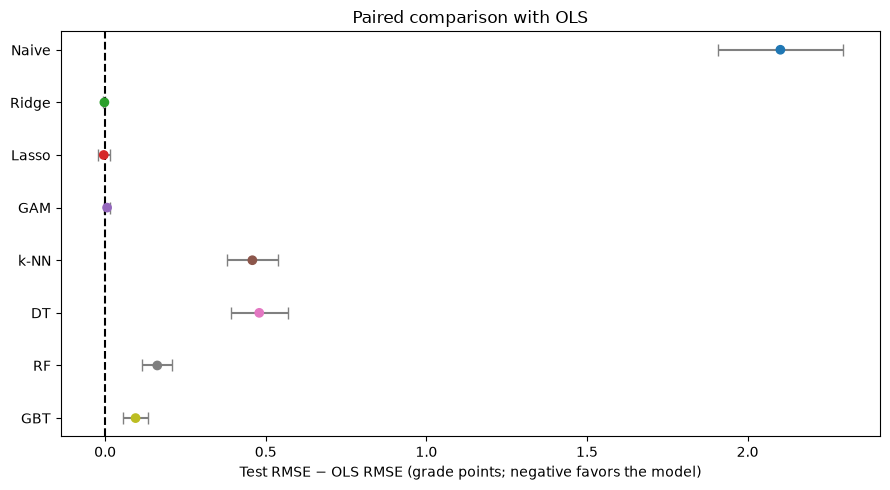

**Comparison with a linear explanation.** Negative differences quantify gains over OLS on the same splits. Intervals use the approximate repeated-split variance correction and are exploratory, not simultaneous. With fewer than two experiments, only point estimates are shown.

In [17]:
from IPython.display import display, Markdown
from scipy.stats import t as t_distribution

# One long-form table per result type; keep existing metric tuples unchanged.
regression_predictions = pd.concat(regression_prediction_records, ignore_index=True)
regression_timings = pd.DataFrame(regression_timing_records)
regression_metrics = pd.concat([
    pd.DataFrame(values, columns=['RMSE', 'MAE', 'R2', 'CV RMSE', 'LogLik'])
      .assign(experiment=lambda frame: np.arange(len(frame)), model=name)
    for name, values in zip(REGRESSION_NAMES, model_error_lists)
], ignore_index=True)
MODEL_COLORS = dict(zip(REGRESSION_NAMES, plt.get_cmap('tab10').colors))

def explain(text):
    display(Markdown(text))

def corrected_rmse_intervals(metric_table, reference):
    """Exploratory paired intervals, corrected approximately for overlapping splits."""
    scores = metric_table.pivot(index='experiment', columns='model', values='RMSE')
    differences = scores.sub(scores[reference], axis=0)
    result = pd.DataFrame({'difference': differences.mean()})
    if len(scores) < 2:
        result['margin'] = np.nan
    else:
        sizes = regression_timings.groupby('experiment')[['train size', 'test size']].first()
        ratio = (sizes.loc[scores.index, 'test size'] / sizes.loc[scores.index, 'train size']).mean()
        result['margin'] = t_distribution.ppf(.975, len(scores) - 1) * np.sqrt(
            (1 / len(scores) + ratio) * differences.var(ddof=1))
    return result

performance_summary = regression_metrics.groupby('model')[['RMSE', 'MAE', 'R2']].agg(['mean', 'std']).reindex(REGRESSION_NAMES)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, metric in zip(axes, ['RMSE', 'MAE', 'R2']):
    means = performance_summary[(metric, 'mean')]
    spread = performance_summary[(metric, 'std')].fillna(0)
    positions = np.arange(len(means))
    ax.errorbar(means, positions, xerr=spread, fmt='none', ecolor='0.65', capsize=3)
    ax.scatter(means, positions, c=[MODEL_COLORS[m] for m in means.index], zorder=3)
    ax.set_yticks(positions, means.index)
    ax.invert_yaxis()
    ax.set(xlabel='R² (higher is better)' if metric == 'R2' else f'{metric} (grade points; lower is better)',
           title=f'Test {metric}: mean ± split SD')
    ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()
display(performance_summary.round(3))
best_rmse_model = performance_summary[('RMSE', 'mean')].idxmin()
explain(f"**Performance.** {best_rmse_model} has the lowest mean test RMSE "
        f"({performance_summary.loc[best_rmse_model, ('RMSE', 'mean')]:.3f} grade points). "
        "Bars show variation across splits, not uncertainty intervals; SD is unavailable for a single run.")

paired_ols = corrected_rmse_intervals(regression_metrics, 'OLS').drop(index='OLS').reindex(
    [m for m in REGRESSION_NAMES if m != 'OLS'])
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(paired_ols['difference'], paired_ols.index,
           c=[MODEL_COLORS[m] for m in paired_ols.index], zorder=3)
if paired_ols['margin'].notna().all():
    ax.errorbar(paired_ols['difference'], paired_ols.index, xerr=paired_ols['margin'],
                fmt='none', ecolor='0.5', capsize=4)
ax.axvline(0, color='black', linestyle='--')
ax.set(xlabel='Test RMSE − OLS RMSE (grade points; negative favors the model)',
       title='Paired comparison with OLS')
ax.invert_yaxis()
plt.tight_layout()
plt.show()
explain("**Comparison with a linear explanation.** Negative differences quantify gains over OLS on the same splits. "
        "Intervals use the approximate repeated-split variance correction and are exploratory, not simultaneous. "
        "With fewer than two experiments, only point estimates are shown.")

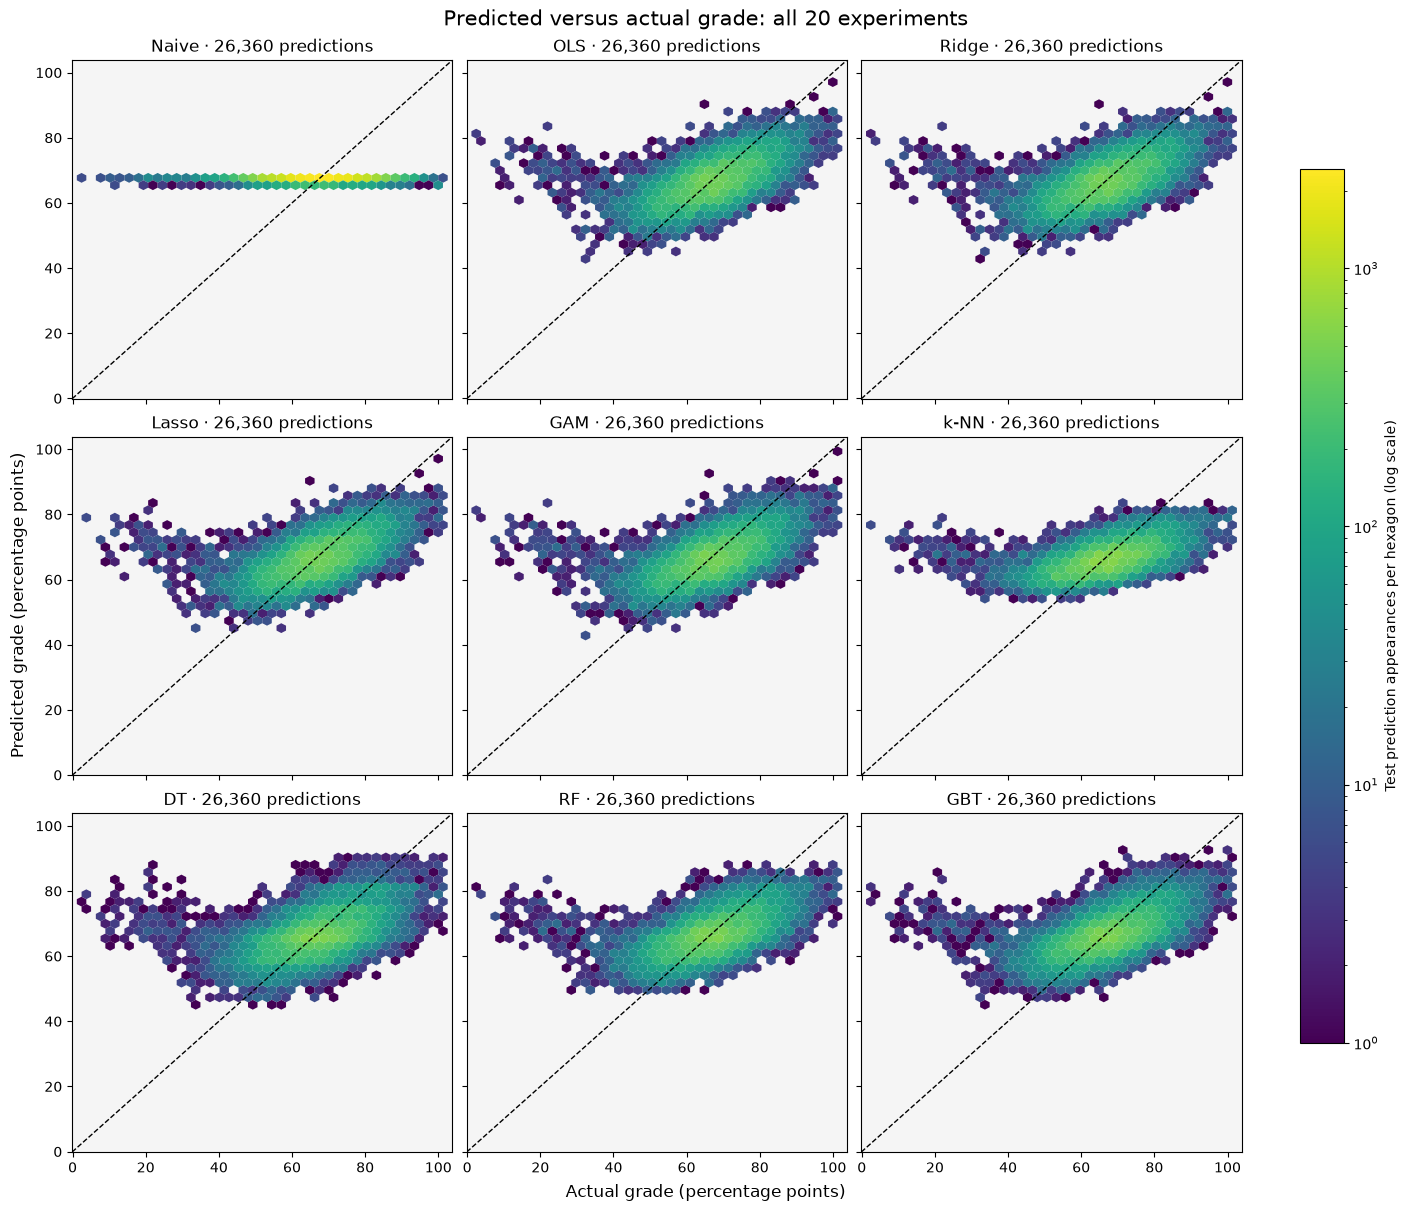

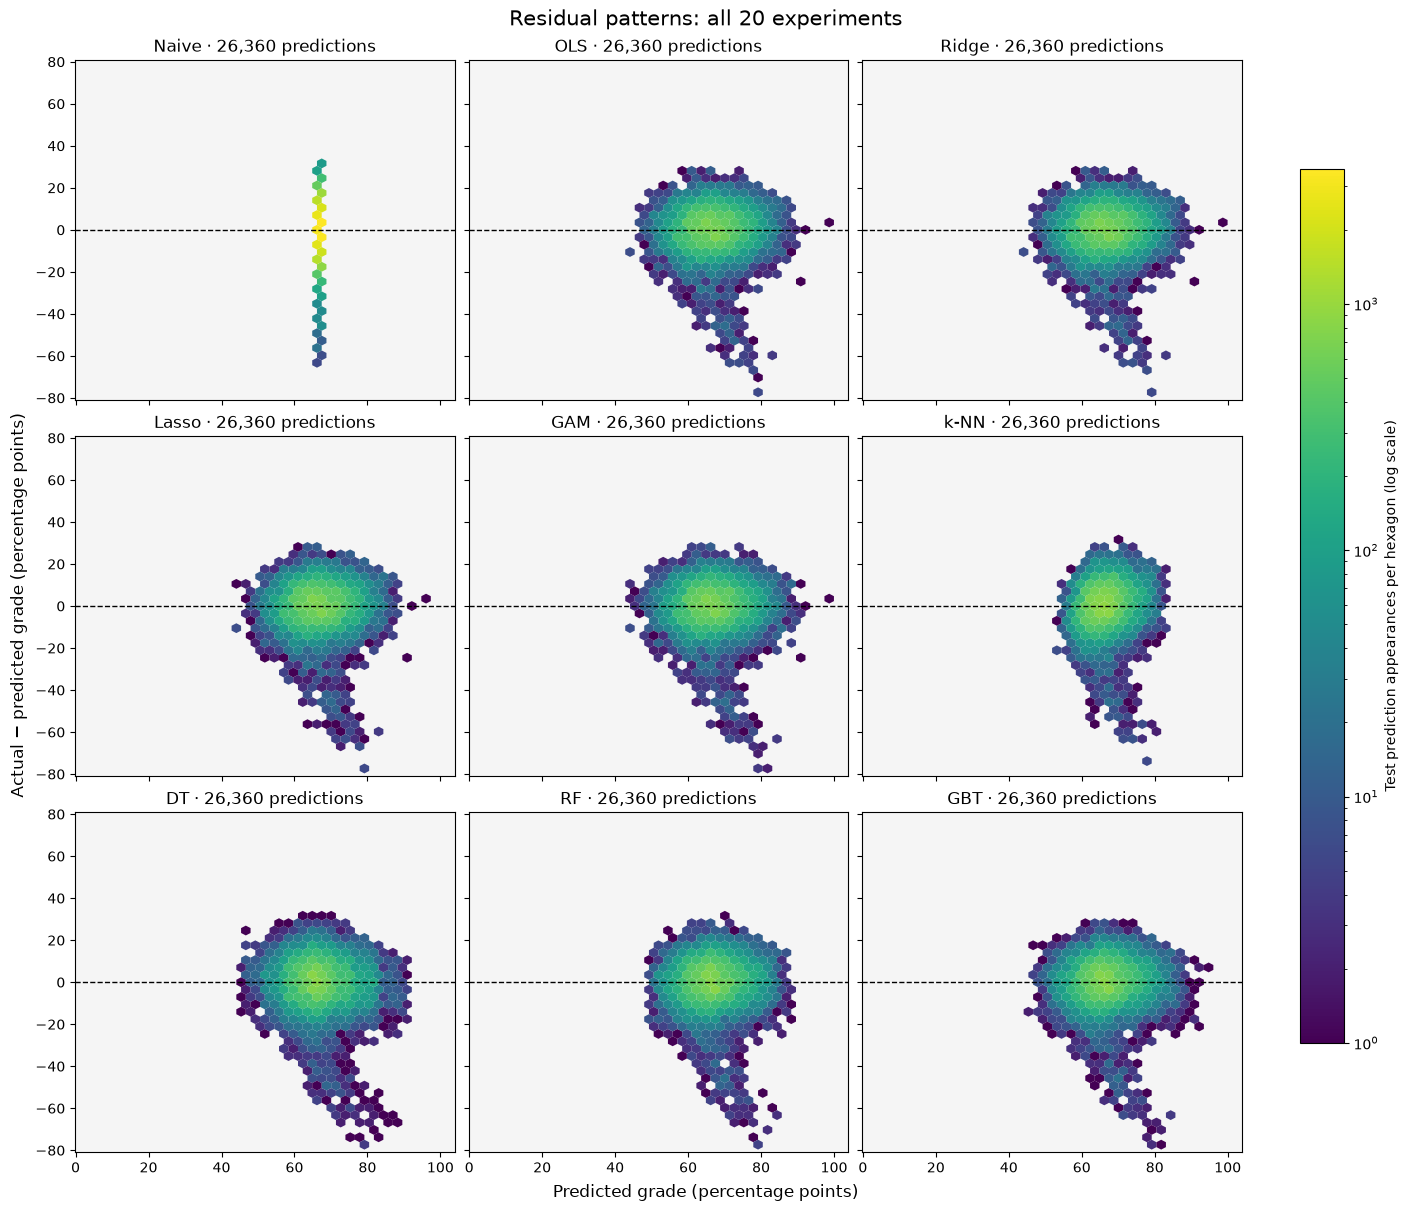

**Error structure across models and splits.** Each panel pools all held-out predictions for one model. The agreement diagonal indicates perfect prediction; positive residuals mean underprediction. Curves, funnels, or persistent offsets suggest missed structure or changing error spread. Shared axes, hexagon locations, and a shared log count scale within each figure make models comparable. Counts include repeated test appearances of the same student across experiments; they are not independent observations. Pooling can hide differences between splits, so use the split-level summaries above to assess stability.

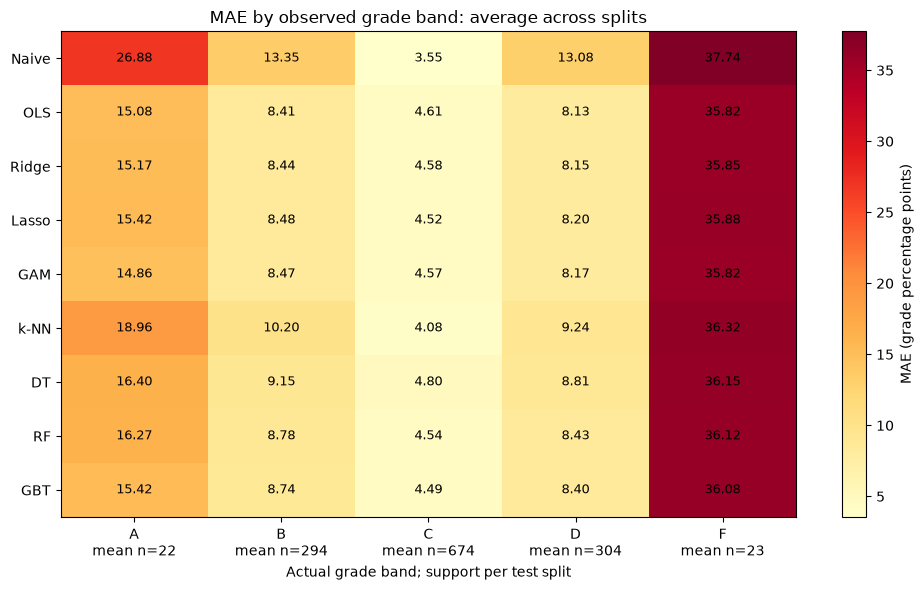

**Who is harder to predict?** Compare models within each column to identify errors hidden by aggregate RMSE. Support counts are mean test observations per split, not unique students across experiments. Rare bands are less stable; absent bands are marked N/A.

In [18]:
from matplotlib.colors import LogNorm

# Pool held-out predictions from every experiment for all nine models.
# A student can contribute once per experiment; counts are prediction appearances.
diagnostic_predictions = regression_predictions.copy()
diagnostic_predictions['residual'] = (diagnostic_predictions['actual']
                                       - diagnostic_predictions['predicted'])
n_diagnostic_experiments = diagnostic_predictions['experiment'].nunique()

def padded_limits(values):
    lower, upper = float(values.min()), float(values.max())
    padding = max((upper - lower) * .03, 1.)
    return lower - padding, upper + padding

grade_limits = padded_limits(pd.concat([all_predictions['actual'], all_predictions['predicted']]))
residual_limit = max(float((all_predictions['actual'] - all_predictions['predicted']).abs().max()) * 1.03, 1.)
residual_limits = (-residual_limit, residual_limit)

for kind in ['agreement', 'residual']:
    fig, axes = plt.subplots(3, 3, figsize=(14, 12), sharex=True, sharey=True,
                             layout='constrained')
    density_plots = []
    # All panels share bin locations and one logarithmic count scale.
    count_norm = LogNorm(vmin=1, vmax=2)
    y_limits = grade_limits if kind == 'agreement' else residual_limits
    for ax, name in zip(axes.flat, REGRESSION_NAMES):
        records = diagnostic_predictions[diagnostic_predictions['model'].eq(name)]
        x = records['actual'] if kind == 'agreement' else records['predicted']
        y = records['predicted'] if kind == 'agreement' else records['residual']
        density = ax.hexbin(x, y, gridsize=40, mincnt=1, cmap='viridis',
                            norm=count_norm, linewidths=0,
                            extent=(*grade_limits, *y_limits), rasterized=True)
        density_plots.append(density)
        if kind == 'agreement':
            ax.plot(grade_limits, grade_limits, color='black', linestyle='--', linewidth=1)
        else:
            ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.set(title=f"{name} · {len(records):,} predictions", xlim=grade_limits, ylim=y_limits)
        ax.set_facecolor('#f5f5f5')
    count_norm.vmax = max(2, max(float(plot.get_array().max()) for plot in density_plots))
    fig.colorbar(density_plots[0], ax=axes.ravel().tolist(), shrink=.8,
                 label='Test prediction appearances per hexagon (log scale)')
    if kind == 'agreement':
        fig.supxlabel('Actual grade (percentage points)')
        fig.supylabel('Predicted grade (percentage points)')
        title = 'Predicted versus actual grade'
    else:
        fig.supxlabel('Predicted grade (percentage points)')
        fig.supylabel('Actual − predicted grade (percentage points)')
        title = 'Residual patterns'
    fig.suptitle(f'{title}: all {n_diagnostic_experiments} experiments', fontsize=15)
    plt.show()

explain("**Error structure across models and splits.** Each panel pools all held-out predictions for one model. "
        "The agreement diagonal indicates perfect prediction; positive residuals mean underprediction. "
        "Curves, funnels, or persistent offsets suggest missed structure or changing error spread. "
        "Shared axes, hexagon locations, and a shared log count scale within each figure make models comparable. "
        "Counts include repeated test appearances of the same student across experiments; they are not independent "
        "observations. Pooling can hide differences between splits, so use the split-level summaries above "
        "to assess stability.")

# Average per-split MAE, rather than treating repeated appearances of students as independent.
regression_predictions['absolute error'] = (regression_predictions['actual'] - regression_predictions['predicted']).abs()
band_order = ['A', 'B', 'C', 'D', 'F']
band_errors = regression_predictions.groupby(['experiment', 'model', 'grade band'])['absolute error'].mean()
band_mae = band_errors.groupby(['model', 'grade band']).mean().unstack().reindex(index=REGRESSION_NAMES, columns=band_order)
band_support = (regression_predictions[regression_predictions['model'].eq('OLS')]
                .groupby(['experiment', 'grade band']).size().unstack(fill_value=0)
                .reindex(columns=band_order, fill_value=0).mean())
fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.get_cmap('YlOrRd').copy()
cmap.set_bad('lightgrey')
image = ax.imshow(np.ma.masked_invalid(band_mae.to_numpy()), cmap=cmap, aspect='auto')
for row in range(len(band_mae)):
    for col in range(len(band_order)):
        value = band_mae.iloc[row, col]
        ax.text(col, row, 'N/A' if pd.isna(value) else f'{value:.2f}', ha='center', va='center', fontsize=9)
ax.set_yticks(range(len(REGRESSION_NAMES)), REGRESSION_NAMES)
ax.set_xticks(range(len(band_order)), [f'{b}\nmean n={band_support[b]:.0f}' for b in band_order])
ax.set(title='MAE by observed grade band: average across splits', xlabel='Actual grade band; support per test split')
fig.colorbar(image, ax=ax, label='MAE (grade percentage points)')
plt.tight_layout()
plt.show()
explain("**Who is harder to predict?** Compare models within each column to identify errors hidden by aggregate RMSE. "
        "Support counts are mean test observations per split, not unique students across experiments. "
        "Rare bands are less stable; absent bands are marked N/A.")

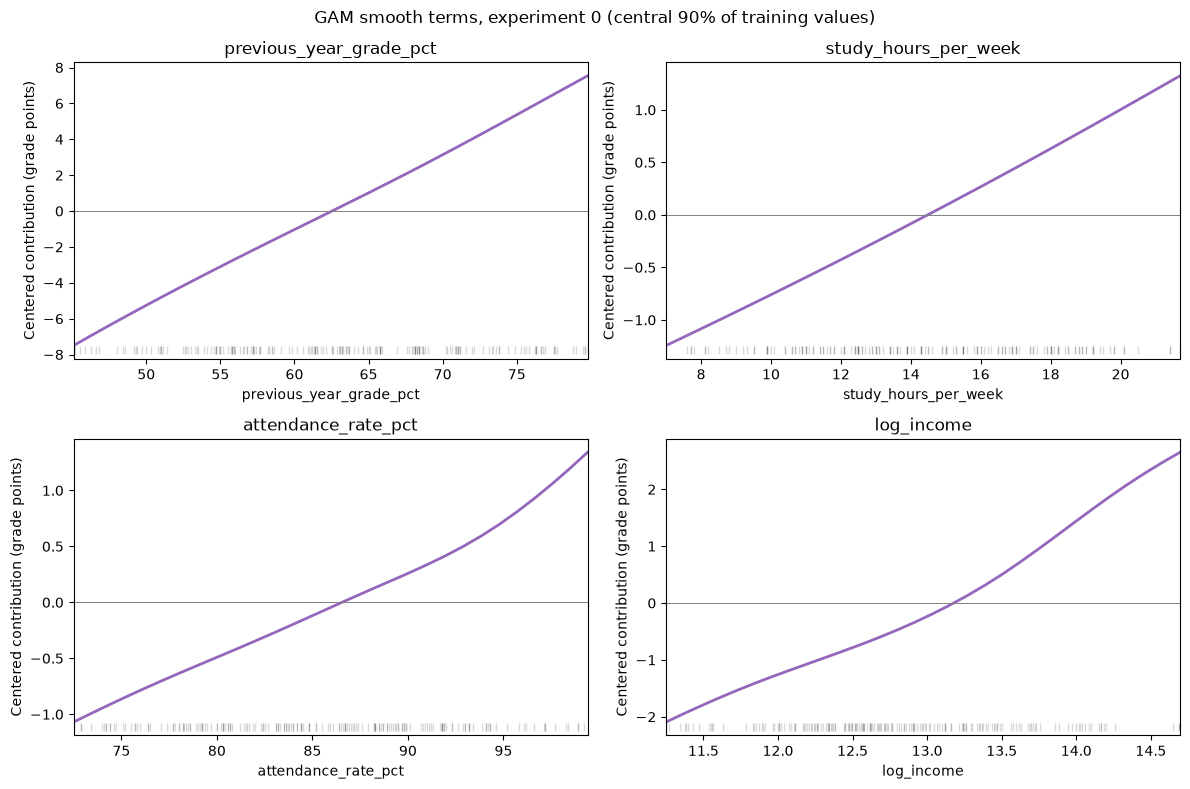

**GAM interpretation.** Each curve shows an additive contribution to predicted grade. Bends indicate nonlinear behavior learned by this fit; the rug shows training support. No inferential bands are shown because this plot does not account for tuning and split uncertainty.

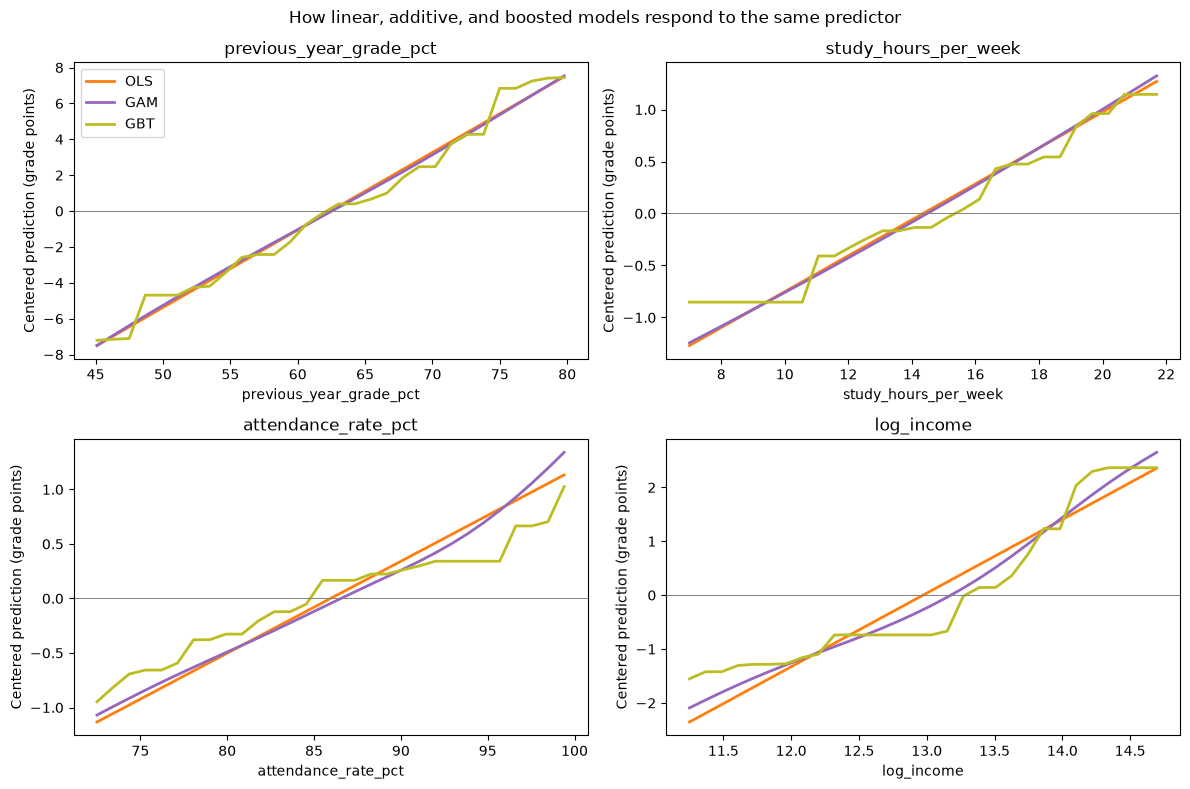

**Linear versus nonlinear response.** OLS provides a straight-line reference; GAM permits smooth additive changes; GBT can capture thresholds and interactions. Similar curves support a simpler description; differences motivate checking residuals and paired performance before preferring a more complex model.

In [19]:
effect_features = ['previous_year_grade_pct', 'study_hours_per_week', 'attendance_rate_pct', 'log_income']
explanation_train = regression_diagnostic_data['X_train']
gam_pipeline = regression_diagnostic_models['GAM']
gam_pipeline = gam_pipeline.regressor_ if hasattr(gam_pipeline, 'regressor_') else gam_pipeline
gam_prep = gam_pipeline.named_steps['prep']
gam = gam_pipeline.named_steps['model'].gam_
encoded_names = list(gam_prep.get_feature_names_out())
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, effect_features):
    feature_index = encoded_names.index('num__' + feature)
    values = explanation_train[feature].to_numpy()
    grid = np.linspace(*np.quantile(values, [.05, .95]), 30)
    design = np.tile(gam_prep.transform(explanation_train.iloc[:1]), (len(grid), 1))
    design[:, feature_index] = grid
    effect = gam.partial_dependence(term=feature_index, X=design)
    ax.plot(grid, effect - effect.mean(), color=MODEL_COLORS['GAM'], linewidth=2)
    rug = np.random.default_rng(0).choice(values, size=min(200, len(values)), replace=False)
    ax.plot(rug, np.full(len(rug), .03), '|', transform=ax.get_xaxis_transform(), alpha=.15, color='black')
    ax.set(xlim=(grid[0], grid[-1]), xlabel=feature, ylabel='Centered contribution (grade points)', title=feature)
    ax.axhline(0, color='grey', linewidth=.7)
fig.suptitle('GAM smooth terms, experiment 0 (central 90% of training values)')
plt.tight_layout()
plt.show()
explain("**GAM interpretation.** Each curve shows an additive contribution to predicted grade. Bends indicate "
        "nonlinear behavior learned by this fit; the rug shows training support. No inferential bands are shown "
        "because this plot does not account for tuning and split uncertainty.")

# Manual marginal averaging works with the existing custom GAM wrapper as well as sklearn models.
explanation_sample = explanation_train.sample(n=min(500, len(explanation_train)), random_state=0)
partial_dependence_records = []
response_names = ['OLS', 'GAM', 'GBT']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, effect_features):
    grid = np.linspace(*explanation_train[feature].quantile([.05, .95]).to_numpy(), 30)
    for name in response_names:
        model = regression_diagnostic_models[name]
        curve = []
        for value in grid:
            altered = explanation_sample.copy()
            altered[feature] = value
            curve.append(np.mean(model.predict(altered)))
        curve = np.asarray(curve)
        centered = curve - curve.mean()
        ax.plot(grid, centered, label=name, color=MODEL_COLORS[name], linewidth=2)
        partial_dependence_records.extend({'model': name, 'feature': feature, 'value': value, 'centered prediction': effect}
                                          for value, effect in zip(grid, centered))
    ax.set(xlabel=feature, ylabel='Centered prediction (grade points)', title=feature)
    ax.axhline(0, color='grey', linewidth=.7)
axes.flat[0].legend()
fig.suptitle('How linear, additive, and boosted models respond to the same predictor')
plt.tight_layout()
plt.show()
explain("**Linear versus nonlinear response.** OLS provides a straight-line reference; GAM permits smooth additive "
        "changes; GBT can capture thresholds and interactions. Similar curves support a simpler description; "
        "differences motivate checking residuals and paired performance before preferring a more complex model.")

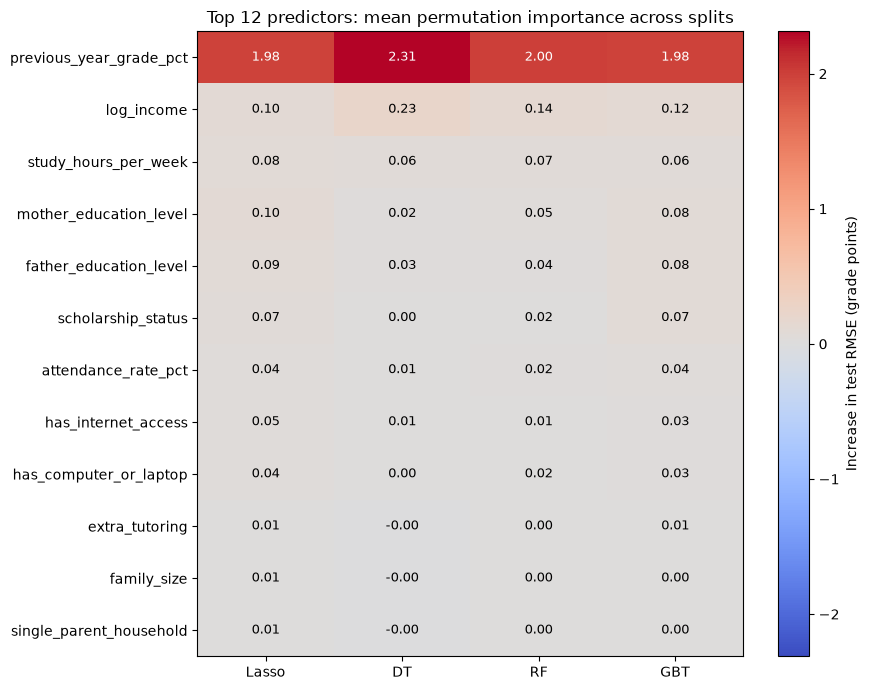

**Importance agreement.** Shared high-importance predictors suggest models rely on similar information. Values retain grade-point units, so this is reliance rather than a normalized rank. Correlated predictors can substitute for each other; near-zero or negative values need cautious interpretation. The existing feature-selection section also shows split-to-split spread.

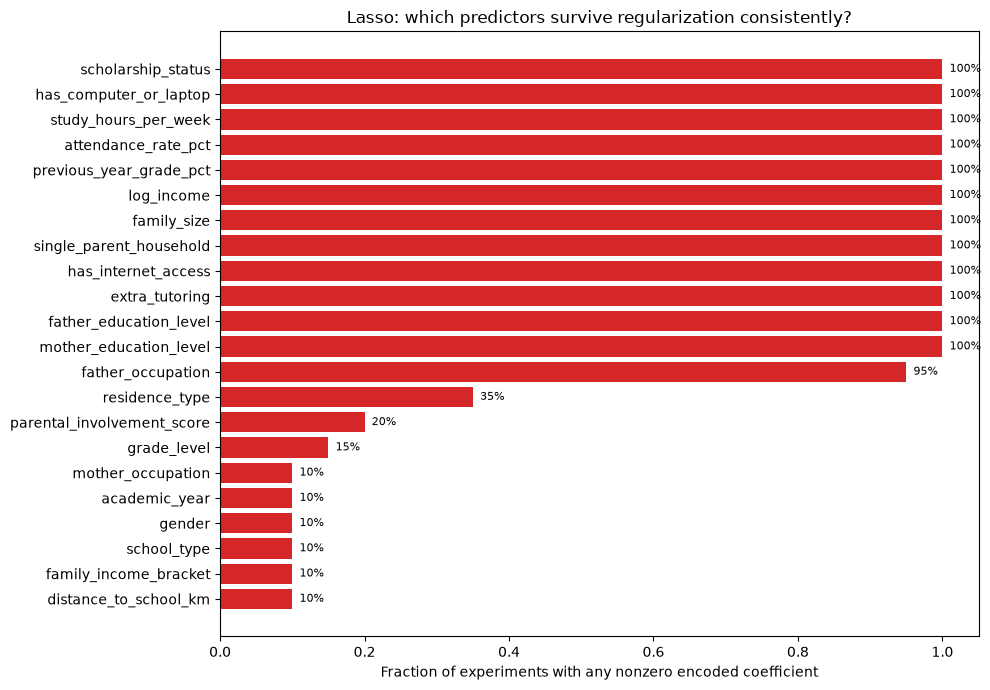

**Selection stability.** A categorical predictor is retained when any encoded level is nonzero. Stable selection does not establish causation or unique importance. Lasso numeric coefficients are grade changes per training SD; ordinal coefficients are per encoded level; one-hot coefficients are relative to the omitted category. Their magnitudes are not on a common scale.

In [20]:
importance_frame = pd.DataFrame(importance_records)
importance_models = ['Lasso', 'DT', 'RF', 'GBT']
importance_means = importance_frame.groupby('model')[PREDICTOR_COLS].mean().reindex(importance_models).T
importance_features = importance_means.mean(axis=1).nlargest(12).index
importance_plot = importance_means.loc[importance_features]
limit = max(float(importance_plot.abs().max().max()), 1e-12)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(importance_plot, aspect='auto', cmap='coolwarm', vmin=-limit, vmax=limit)
ax.set_xticks(range(len(importance_models)), importance_models)
ax.set_yticks(range(len(importance_features)), importance_features)
for row in range(len(importance_features)):
    for col in range(len(importance_models)):
        value = importance_plot.iloc[row, col]
        ax.text(col, row, f'{value:.2f}', ha='center', va='center',
                color='white' if abs(value) > .6 * limit else 'black', fontsize=9)
ax.set_title('Top 12 predictors: mean permutation importance across splits')
fig.colorbar(image, ax=ax, label='Increase in test RMSE (grade points)')
plt.tight_layout()
plt.show()
explain("**Importance agreement.** Shared high-importance predictors suggest models rely on similar information. "
        "Values retain grade-point units, so this is reliance rather than a normalized rank. Correlated predictors "
        "can substitute for each other; near-zero or negative values need cautious interpretation. "
        "The existing feature-selection section also shows split-to-split spread.")

lasso_stability = pd.DataFrame(lasso_selection_records).drop(columns='experiment').mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(lasso_stability.index, lasso_stability, color=MODEL_COLORS['Lasso'])
ax.set(xlim=(0, 1.05), xlabel='Fraction of experiments with any nonzero encoded coefficient',
       title='Lasso: which predictors survive regularization consistently?')
for position, value in enumerate(lasso_stability):
    ax.text(value + .01, position, f'{value:.0%}', va='center', fontsize=8)
plt.tight_layout()
plt.show()
explain("**Selection stability.** A categorical predictor is retained when any encoded level is nonzero. "
        "Stable selection does not establish causation or unique importance. Lasso numeric coefficients are "
        "grade changes per training SD; ordinal coefficients are per encoded level; one-hot coefficients are "
        "relative to the omitted category. Their magnitudes are not on a common scale.")

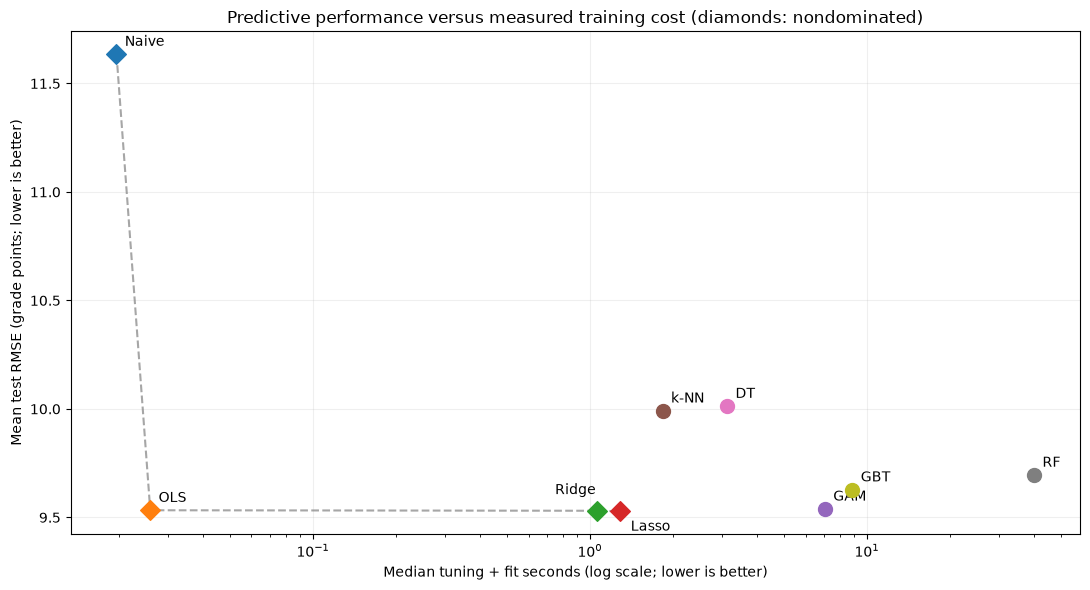

,mean test RMSE,median tuning + fit seconds,median prediction seconds,nondominated
model,,,,
Naive,11.6350,0.0195,0.0052,True
OLS,9.5330,0.0259,0.0052,True
Ridge,9.5307,1.0580,0.0052,True
Lasso,9.5287,1.2797,0.0054,True
GAM,9.5390,7.0513,0.0121,False
k-NN,9.9913,1.8304,0.0898,False
DT,10.0127,3.1276,0.0047,False
RF,9.6953,40.1144,0.0167,False
GBT,9.6277,8.8624,0.0085,False


**Computational tradeoff.** Diamonds identify models for which no alternative is both at least as fast and at least as accurate, with one strict improvement. These are empirical means and medians, not uncertainty-aware dominance claims. Timing includes each existing search budget and final refit; RF uses five CV folds while most tuned regressors use ten. Machine, parallelism, and grid size affect the comparison. Prediction timings cover one complete test batch and can be noisy.

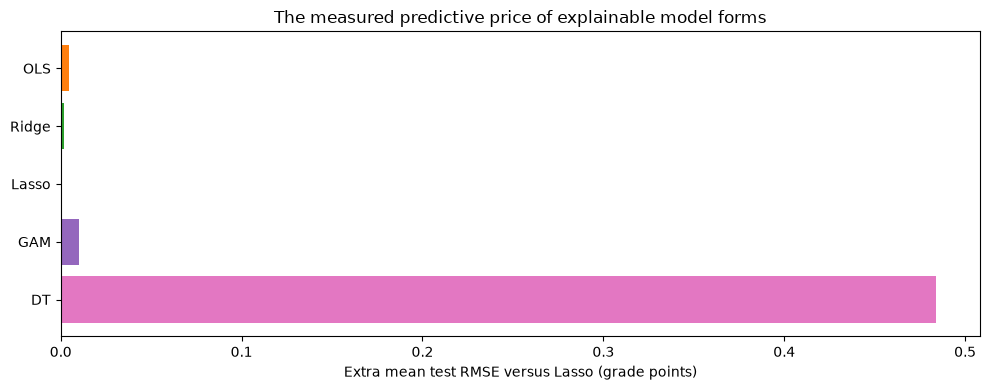

,extra RMSE (grade points),extra RMSE (%),explanation form
model,,,
OLS,0.004,0.045,Linear coefficients
Ridge,0.002,0.021,Regularized linear coefficients
Lasso,0.000,0.000,Sparse linear coefficients
GAM,0.010,0.109,Additive smooth curves
DT,0.484,5.080,Decision rules (readability depends on tree size)


**Interpretability price.** Among the listed model forms, Lasso has the smallest RMSE penalty (0.000 grade points) relative to Lasso. The reference was selected from these test results, so this penalty is descriptive. Interpretability depends on the audience and fitted complexity; no numerical interpretability score is assigned. Small gaps should be read alongside the paired intervals and residual plots.

In [21]:
runtime_summary = regression_timings.groupby('model')[['fit seconds', 'prediction seconds']].median().reindex(REGRESSION_NAMES)
tradeoff_summary = pd.DataFrame({
    'mean test RMSE': performance_summary[('RMSE', 'mean')],
    'median tuning + fit seconds': runtime_summary['fit seconds'],
    'median prediction seconds': runtime_summary['prediction seconds'],
})
costs = tradeoff_summary[['median tuning + fit seconds', 'mean test RMSE']].to_numpy()
tradeoff_summary['nondominated'] = [
    not any(np.all(other <= point) and np.any(other < point) for other in costs)
    for point in costs
]
fig, ax = plt.subplots(figsize=(11, 6))
for name, row in tradeoff_summary.iterrows():
    ax.scatter(max(row['median tuning + fit seconds'], 1e-9), row['mean test RMSE'],
               color=MODEL_COLORS[name], s=100,
               marker='D' if row['nondominated'] else 'o', zorder=3)
    ax.annotate(name, (max(row['median tuning + fit seconds'], 1e-9), row['mean test RMSE']),
                xytext={'Ridge': (-30, 12), 'Lasso': (8, -14)}.get(name, (6, 6)),
                textcoords='offset points')
frontier = tradeoff_summary[tradeoff_summary['nondominated']].sort_values('median tuning + fit seconds')
ax.plot(frontier['median tuning + fit seconds'].clip(lower=1e-9), frontier['mean test RMSE'],
        linestyle='--', color='grey', alpha=.7)
ax.set_xscale('log')
ax.set(xlabel='Median tuning + fit seconds (log scale; lower is better)',
       ylabel='Mean test RMSE (grade points; lower is better)',
       title='Predictive performance versus measured training cost (diamonds: nondominated)')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
display(tradeoff_summary.round(4))
explain("**Computational tradeoff.** Diamonds identify models for which no alternative is both at least as fast "
        "and at least as accurate, with one strict improvement. These are empirical means and medians, not "
        "uncertainty-aware dominance claims. Timing includes each existing search budget and final refit; "
        "RF uses five CV folds while most tuned regressors use ten. Machine, parallelism, and grid size affect "
        "the comparison. Prediction timings cover one complete test batch and can be noisy.")

interpretable_names = ['OLS', 'Ridge', 'Lasso', 'GAM', 'DT']
best_rmse = performance_summary.loc[best_rmse_model, ('RMSE', 'mean')]
interpretability_cost = pd.DataFrame({
    'extra RMSE (grade points)': performance_summary.loc[interpretable_names, ('RMSE', 'mean')] - best_rmse,
})
interpretability_cost['extra RMSE (%)'] = (
    100 * interpretability_cost['extra RMSE (grade points)'] / best_rmse if best_rmse > 0 else np.nan)
interpretability_cost['explanation form'] = [
    'Linear coefficients', 'Regularized linear coefficients', 'Sparse linear coefficients',
    'Additive smooth curves', 'Decision rules (readability depends on tree size)',
]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(interpretability_cost.index, interpretability_cost['extra RMSE (grade points)'],
        color=[MODEL_COLORS[m] for m in interpretable_names])
ax.set(xlabel=f'Extra mean test RMSE versus {best_rmse_model} (grade points)',
       title='The measured predictive price of explainable model forms')
ax.invert_yaxis()
plt.tight_layout()
plt.show()
display(interpretability_cost.round(3))
lowest_penalty = interpretability_cost['extra RMSE (grade points)'].idxmin()
explain(f"**Interpretability price.** Among the listed model forms, {lowest_penalty} has the smallest RMSE "
        f"penalty ({interpretability_cost.loc[lowest_penalty, 'extra RMSE (grade points)']:.3f} grade points) "
        f"relative to {best_rmse_model}. The reference was selected from these test results, so this penalty "
        "is descriptive. Interpretability depends on the audience and fitted complexity; no numerical "
        "interpretability score is assigned. Small gaps should be read alongside the paired intervals and residual plots.")

In [22]:
coefficients = pd.DataFrame([{k:v for k,v in p.items() if k not in ['experiment','condition','model']}
    for r in results for p in r['coefficients'] if p['condition']==condition])
coefficient_summary = pd.DataFrame({'mean coefficient':coefficients.mean(), 'split SD':coefficients.std()})
display(coefficient_summary.reindex(coefficient_summary['mean coefficient'].abs().nlargest(15).index).round(3))
print('Coefficient units:', 'square-root grades' if condition=='Sqrt' else 'grade points')

,mean coefficient,split SD
num__previous_year_grade_pct,4.502,0.030
ordinal__scholarship_status,1.198,0.116
num__log_income,0.950,0.081
num__study_hours_per_week,0.802,0.063
ordinal__mother_education_level,0.639,0.042
num__has_internet_access,0.631,0.041
num__has_computer_or_laptop,0.582,0.045
ordinal__father_education_level,0.577,0.037
num__attendance_rate_pct,0.570,0.066
num__extra_tutoring,0.337,0.052


Coefficient units: grade points


## Sqrt: detailed regression diagnostics

All errors and prediction-response curves use original grade points. GAM contributions and Lasso coefficients use the latent square-root scale; they are not additive grade-point changes.

In [23]:
condition = 'Sqrt'
regression_prediction_records = [p for r in results for p in r['predictions'] if p['condition'].iloc[0] == condition]
regression_timing_records = [p for r in results for p in r['timings'] if p['condition'] == condition]
model_error_lists = [all_metrics[(all_metrics.condition == condition) & (all_metrics.model == m)].sort_values('experiment')[['RMSE','MAE','R2','CV RMSE','LogLik']].to_numpy() for m in NAMES]
regression_diagnostic_models = {m:results[0]['models'][(condition,m)] for m in NAMES}
regression_diagnostic_data = results[0]['data']
importance_records = [p for r in results for p in r['importance'] if p['condition']==condition]
lasso_selection_records = [{k:v for k,v in p.items() if k not in ['condition','model']} for r in results for p in r['selections'] if p['condition']==condition]


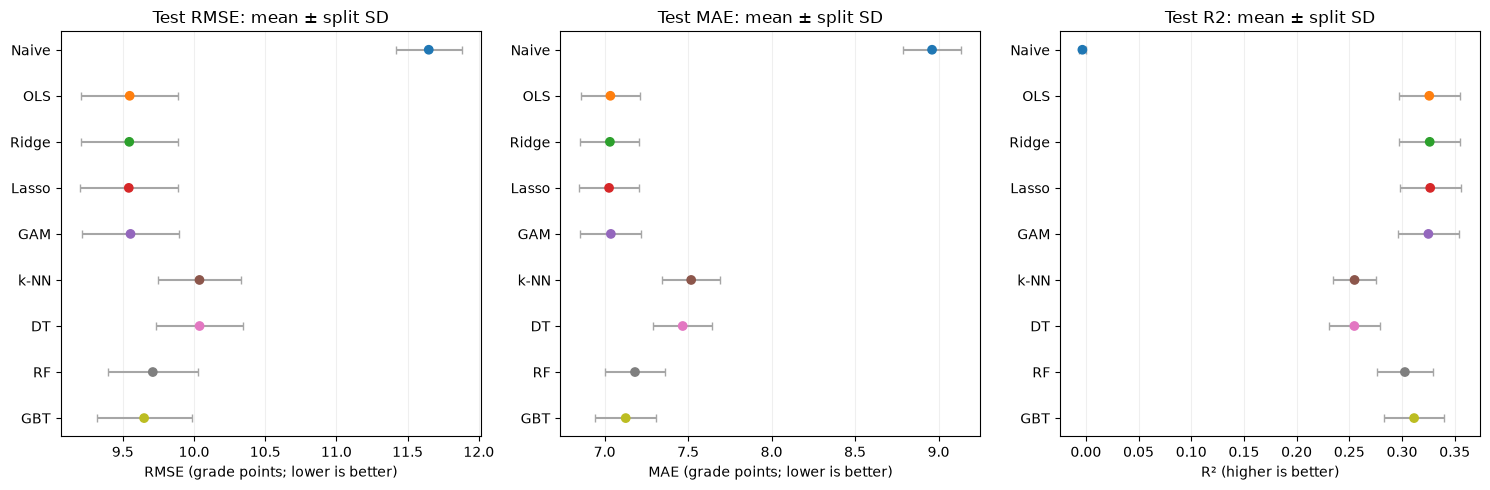

RMSE           MAE            R2       
         mean    std   mean    std   mean    std
model                                           
Naive  11.649  0.231  8.961  0.175 -0.003  0.003
OLS     9.548  0.342  7.034  0.178  0.326  0.029
Ridge   9.545  0.342  7.032  0.177  0.326  0.029
Lasso   9.542  0.344  7.027  0.177  0.327  0.029
GAM     9.554  0.343  7.037  0.182  0.325  0.029
k-NN   10.038  0.293  7.518  0.173  0.255  0.020
DT     10.039  0.306  7.468  0.178  0.255  0.024
RF      9.711  0.318  7.182  0.177  0.303  0.026
GBT     9.650  0.334  7.126  0.182  0.311  0.028

**Performance.** Lasso has the lowest mean test RMSE (9.542 grade points). Bars show variation across splits, not uncertainty intervals; SD is unavailable for a single run.

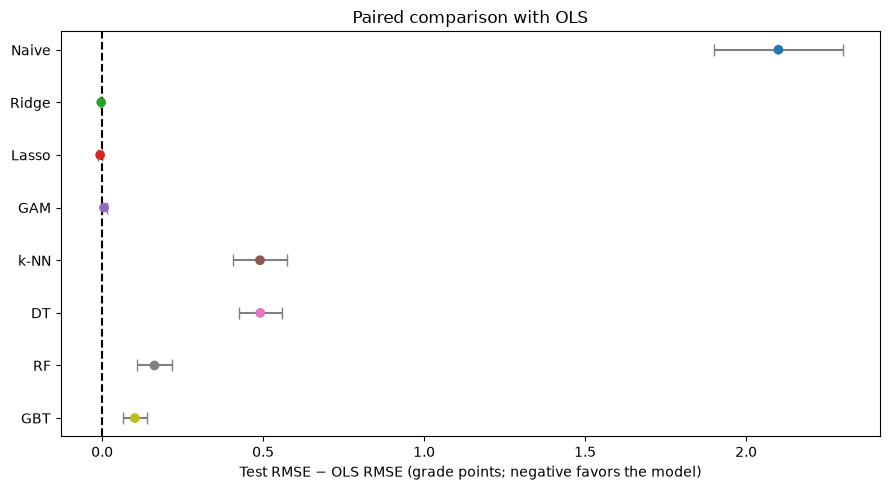

**Comparison with a linear explanation.** Negative differences quantify gains over OLS on the same splits. Intervals use the approximate repeated-split variance correction and are exploratory, not simultaneous. With fewer than two experiments, only point estimates are shown.

In [24]:
from IPython.display import display, Markdown
from scipy.stats import t as t_distribution

# One long-form table per result type; keep existing metric tuples unchanged.
regression_predictions = pd.concat(regression_prediction_records, ignore_index=True)
regression_timings = pd.DataFrame(regression_timing_records)
regression_metrics = pd.concat([
    pd.DataFrame(values, columns=['RMSE', 'MAE', 'R2', 'CV RMSE', 'LogLik'])
      .assign(experiment=lambda frame: np.arange(len(frame)), model=name)
    for name, values in zip(REGRESSION_NAMES, model_error_lists)
], ignore_index=True)
MODEL_COLORS = dict(zip(REGRESSION_NAMES, plt.get_cmap('tab10').colors))

def explain(text):
    display(Markdown(text))

def corrected_rmse_intervals(metric_table, reference):
    """Exploratory paired intervals, corrected approximately for overlapping splits."""
    scores = metric_table.pivot(index='experiment', columns='model', values='RMSE')
    differences = scores.sub(scores[reference], axis=0)
    result = pd.DataFrame({'difference': differences.mean()})
    if len(scores) < 2:
        result['margin'] = np.nan
    else:
        sizes = regression_timings.groupby('experiment')[['train size', 'test size']].first()
        ratio = (sizes.loc[scores.index, 'test size'] / sizes.loc[scores.index, 'train size']).mean()
        result['margin'] = t_distribution.ppf(.975, len(scores) - 1) * np.sqrt(
            (1 / len(scores) + ratio) * differences.var(ddof=1))
    return result

performance_summary = regression_metrics.groupby('model')[['RMSE', 'MAE', 'R2']].agg(['mean', 'std']).reindex(REGRESSION_NAMES)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, metric in zip(axes, ['RMSE', 'MAE', 'R2']):
    means = performance_summary[(metric, 'mean')]
    spread = performance_summary[(metric, 'std')].fillna(0)
    positions = np.arange(len(means))
    ax.errorbar(means, positions, xerr=spread, fmt='none', ecolor='0.65', capsize=3)
    ax.scatter(means, positions, c=[MODEL_COLORS[m] for m in means.index], zorder=3)
    ax.set_yticks(positions, means.index)
    ax.invert_yaxis()
    ax.set(xlabel='R² (higher is better)' if metric == 'R2' else f'{metric} (grade points; lower is better)',
           title=f'Test {metric}: mean ± split SD')
    ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()
display(performance_summary.round(3))
best_rmse_model = performance_summary[('RMSE', 'mean')].idxmin()
explain(f"**Performance.** {best_rmse_model} has the lowest mean test RMSE "
        f"({performance_summary.loc[best_rmse_model, ('RMSE', 'mean')]:.3f} grade points). "
        "Bars show variation across splits, not uncertainty intervals; SD is unavailable for a single run.")

paired_ols = corrected_rmse_intervals(regression_metrics, 'OLS').drop(index='OLS').reindex(
    [m for m in REGRESSION_NAMES if m != 'OLS'])
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(paired_ols['difference'], paired_ols.index,
           c=[MODEL_COLORS[m] for m in paired_ols.index], zorder=3)
if paired_ols['margin'].notna().all():
    ax.errorbar(paired_ols['difference'], paired_ols.index, xerr=paired_ols['margin'],
                fmt='none', ecolor='0.5', capsize=4)
ax.axvline(0, color='black', linestyle='--')
ax.set(xlabel='Test RMSE − OLS RMSE (grade points; negative favors the model)',
       title='Paired comparison with OLS')
ax.invert_yaxis()
plt.tight_layout()
plt.show()
explain("**Comparison with a linear explanation.** Negative differences quantify gains over OLS on the same splits. "
        "Intervals use the approximate repeated-split variance correction and are exploratory, not simultaneous. "
        "With fewer than two experiments, only point estimates are shown.")

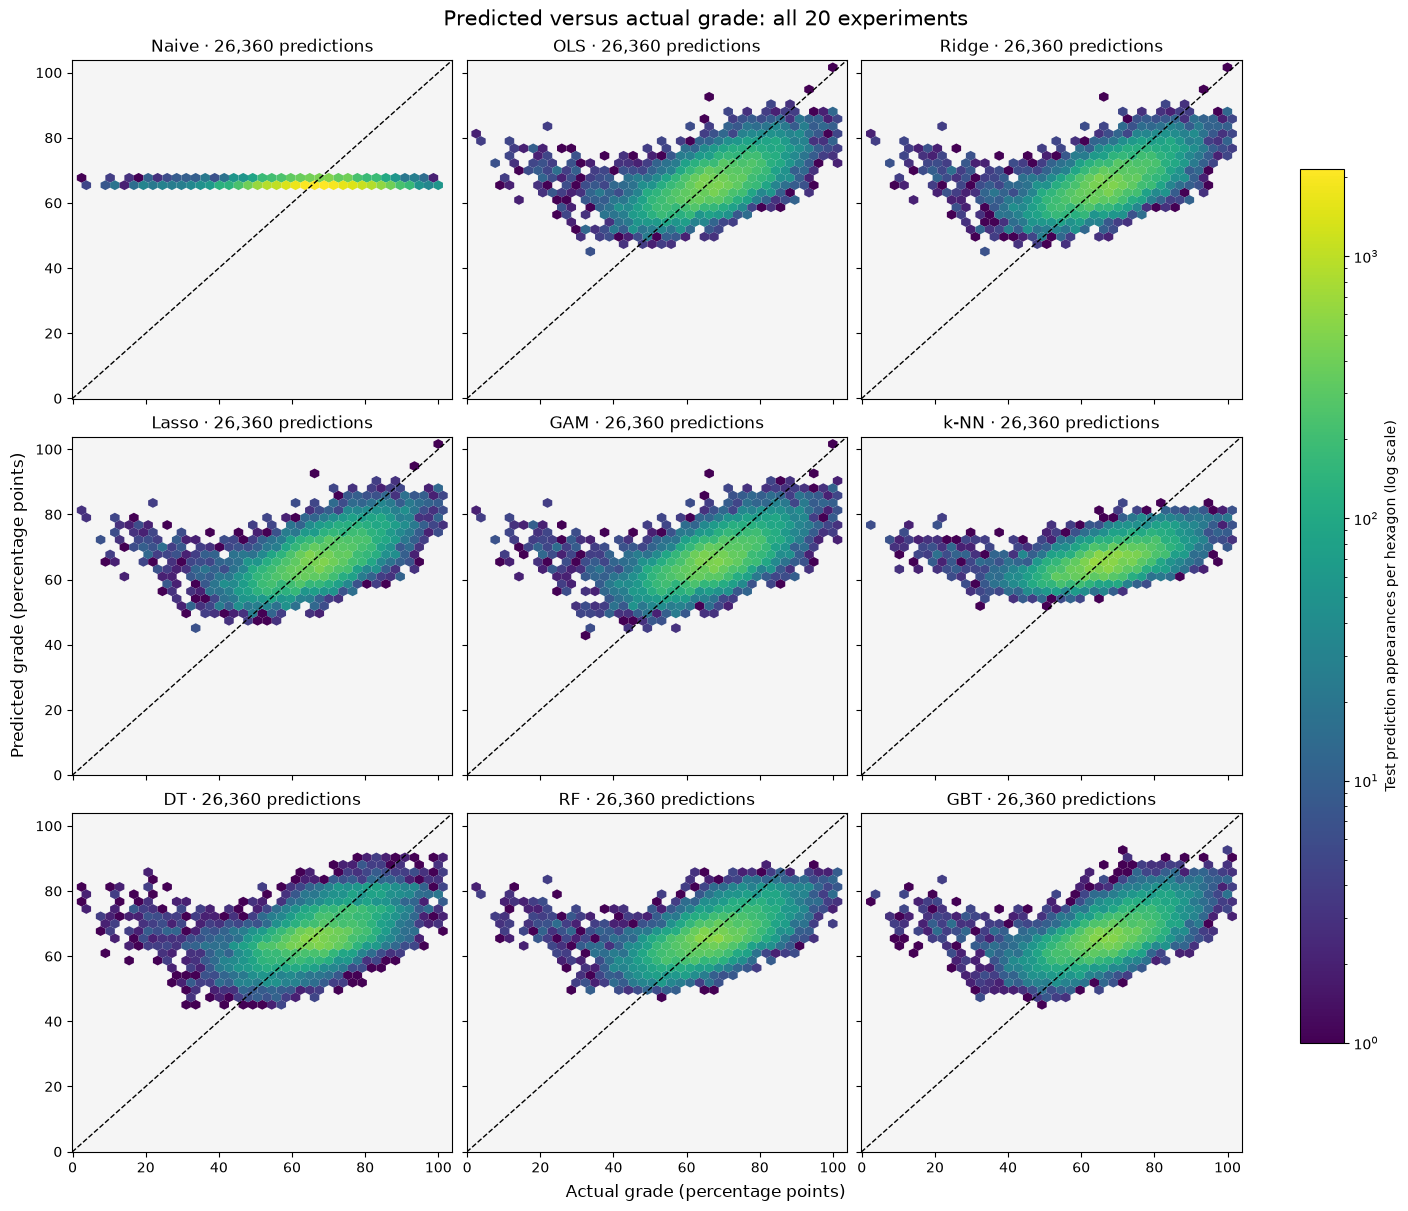

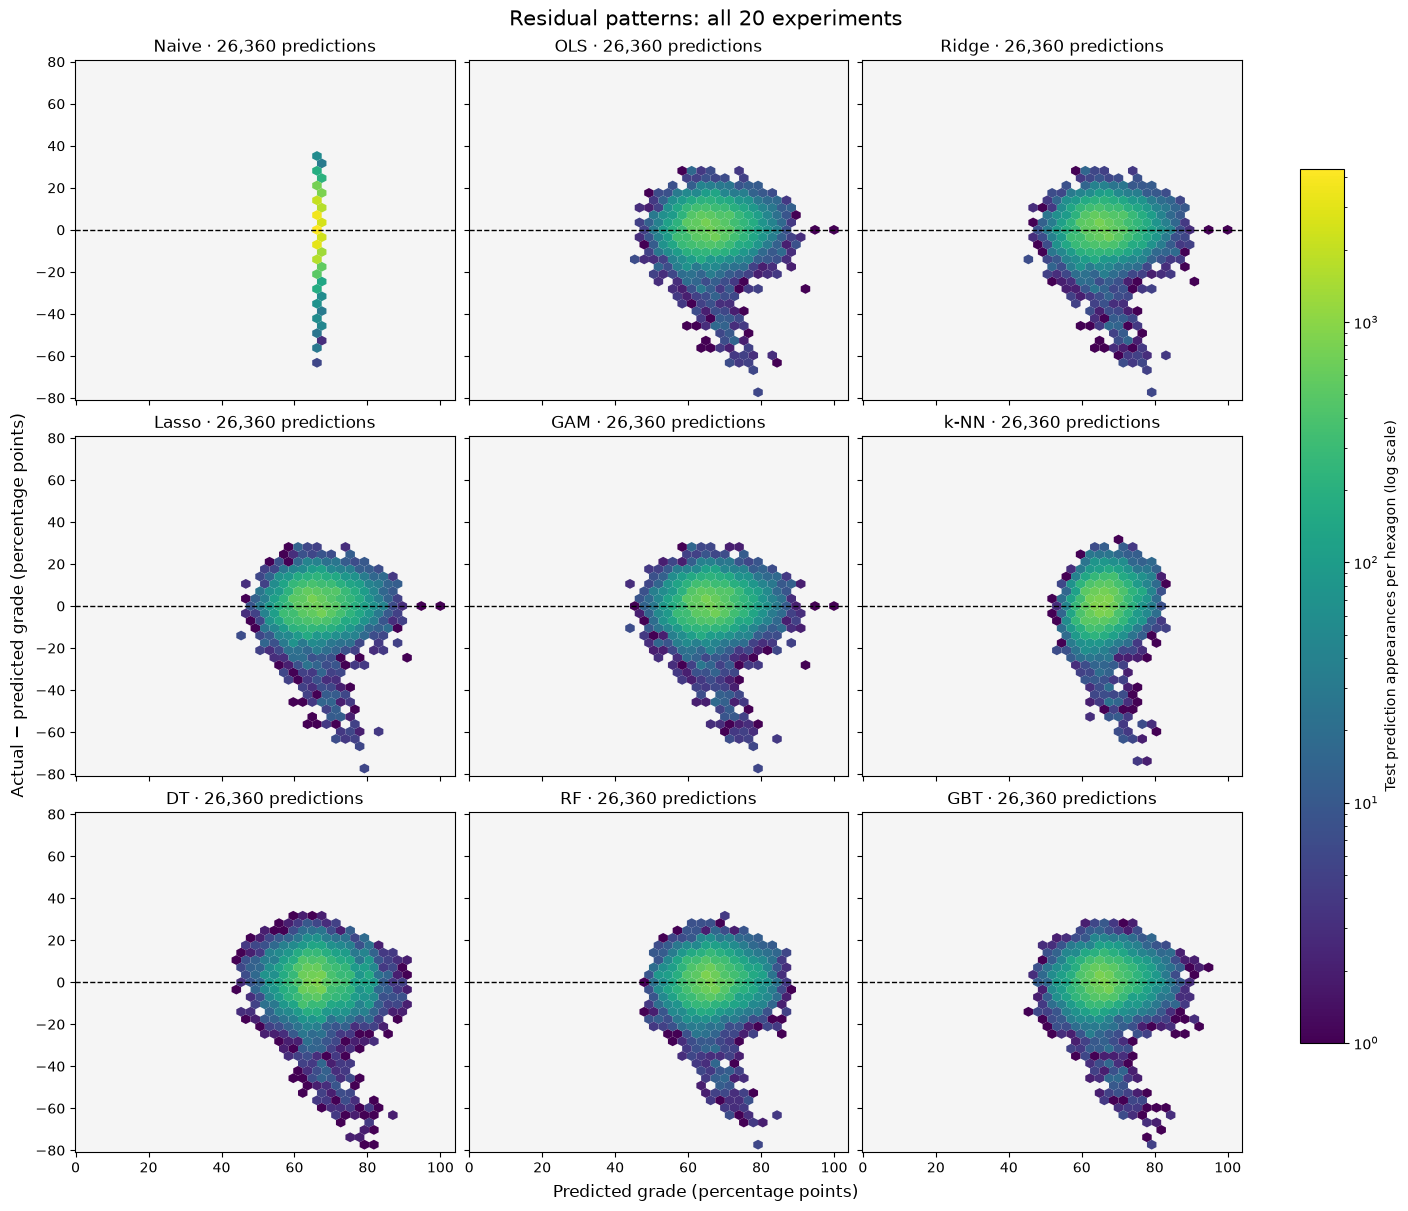

**Error structure across models and splits.** Each panel pools all held-out predictions for one model. The agreement diagonal indicates perfect prediction; positive residuals mean underprediction. Curves, funnels, or persistent offsets suggest missed structure or changing error spread. Shared axes, hexagon locations, and a shared log count scale within each figure make models comparable. Counts include repeated test appearances of the same student across experiments; they are not independent observations. Pooling can hide differences between splits, so use the split-level summaries above to assess stability.

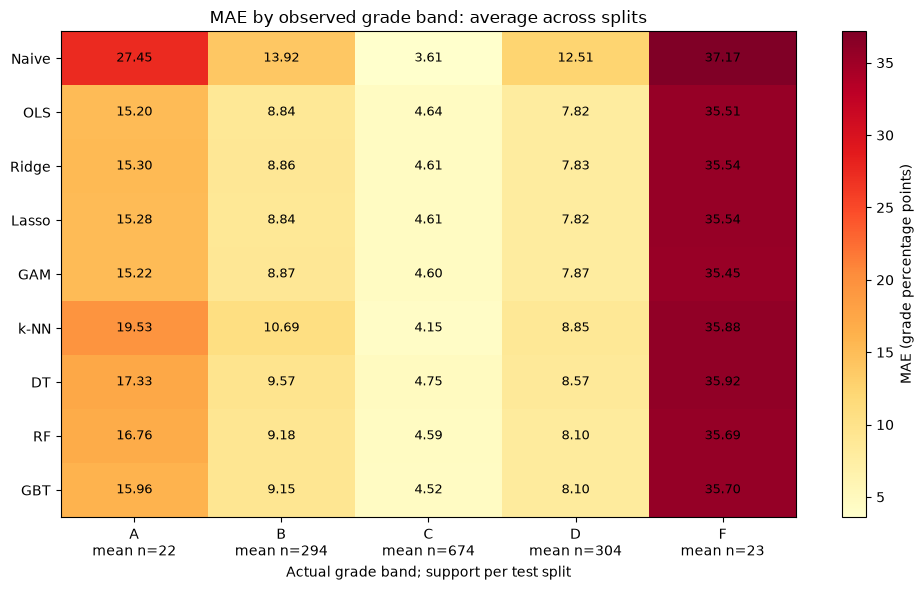

**Who is harder to predict?** Compare models within each column to identify errors hidden by aggregate RMSE. Support counts are mean test observations per split, not unique students across experiments. Rare bands are less stable; absent bands are marked N/A.

In [25]:
from matplotlib.colors import LogNorm

# Pool held-out predictions from every experiment for all nine models.
# A student can contribute once per experiment; counts are prediction appearances.
diagnostic_predictions = regression_predictions.copy()
diagnostic_predictions['residual'] = (diagnostic_predictions['actual']
                                       - diagnostic_predictions['predicted'])
n_diagnostic_experiments = diagnostic_predictions['experiment'].nunique()

def padded_limits(values):
    lower, upper = float(values.min()), float(values.max())
    padding = max((upper - lower) * .03, 1.)
    return lower - padding, upper + padding

grade_limits = padded_limits(pd.concat([all_predictions['actual'], all_predictions['predicted']]))
residual_limit = max(float((all_predictions['actual'] - all_predictions['predicted']).abs().max()) * 1.03, 1.)
residual_limits = (-residual_limit, residual_limit)

for kind in ['agreement', 'residual']:
    fig, axes = plt.subplots(3, 3, figsize=(14, 12), sharex=True, sharey=True,
                             layout='constrained')
    density_plots = []
    # All panels share bin locations and one logarithmic count scale.
    count_norm = LogNorm(vmin=1, vmax=2)
    y_limits = grade_limits if kind == 'agreement' else residual_limits
    for ax, name in zip(axes.flat, REGRESSION_NAMES):
        records = diagnostic_predictions[diagnostic_predictions['model'].eq(name)]
        x = records['actual'] if kind == 'agreement' else records['predicted']
        y = records['predicted'] if kind == 'agreement' else records['residual']
        density = ax.hexbin(x, y, gridsize=40, mincnt=1, cmap='viridis',
                            norm=count_norm, linewidths=0,
                            extent=(*grade_limits, *y_limits), rasterized=True)
        density_plots.append(density)
        if kind == 'agreement':
            ax.plot(grade_limits, grade_limits, color='black', linestyle='--', linewidth=1)
        else:
            ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.set(title=f"{name} · {len(records):,} predictions", xlim=grade_limits, ylim=y_limits)
        ax.set_facecolor('#f5f5f5')
    count_norm.vmax = max(2, max(float(plot.get_array().max()) for plot in density_plots))
    fig.colorbar(density_plots[0], ax=axes.ravel().tolist(), shrink=.8,
                 label='Test prediction appearances per hexagon (log scale)')
    if kind == 'agreement':
        fig.supxlabel('Actual grade (percentage points)')
        fig.supylabel('Predicted grade (percentage points)')
        title = 'Predicted versus actual grade'
    else:
        fig.supxlabel('Predicted grade (percentage points)')
        fig.supylabel('Actual − predicted grade (percentage points)')
        title = 'Residual patterns'
    fig.suptitle(f'{title}: all {n_diagnostic_experiments} experiments', fontsize=15)
    plt.show()

explain("**Error structure across models and splits.** Each panel pools all held-out predictions for one model. "
        "The agreement diagonal indicates perfect prediction; positive residuals mean underprediction. "
        "Curves, funnels, or persistent offsets suggest missed structure or changing error spread. "
        "Shared axes, hexagon locations, and a shared log count scale within each figure make models comparable. "
        "Counts include repeated test appearances of the same student across experiments; they are not independent "
        "observations. Pooling can hide differences between splits, so use the split-level summaries above "
        "to assess stability.")

# Average per-split MAE, rather than treating repeated appearances of students as independent.
regression_predictions['absolute error'] = (regression_predictions['actual'] - regression_predictions['predicted']).abs()
band_order = ['A', 'B', 'C', 'D', 'F']
band_errors = regression_predictions.groupby(['experiment', 'model', 'grade band'])['absolute error'].mean()
band_mae = band_errors.groupby(['model', 'grade band']).mean().unstack().reindex(index=REGRESSION_NAMES, columns=band_order)
band_support = (regression_predictions[regression_predictions['model'].eq('OLS')]
                .groupby(['experiment', 'grade band']).size().unstack(fill_value=0)
                .reindex(columns=band_order, fill_value=0).mean())
fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.get_cmap('YlOrRd').copy()
cmap.set_bad('lightgrey')
image = ax.imshow(np.ma.masked_invalid(band_mae.to_numpy()), cmap=cmap, aspect='auto')
for row in range(len(band_mae)):
    for col in range(len(band_order)):
        value = band_mae.iloc[row, col]
        ax.text(col, row, 'N/A' if pd.isna(value) else f'{value:.2f}', ha='center', va='center', fontsize=9)
ax.set_yticks(range(len(REGRESSION_NAMES)), REGRESSION_NAMES)
ax.set_xticks(range(len(band_order)), [f'{b}\nmean n={band_support[b]:.0f}' for b in band_order])
ax.set(title='MAE by observed grade band: average across splits', xlabel='Actual grade band; support per test split')
fig.colorbar(image, ax=ax, label='MAE (grade percentage points)')
plt.tight_layout()
plt.show()
explain("**Who is harder to predict?** Compare models within each column to identify errors hidden by aggregate RMSE. "
        "Support counts are mean test observations per split, not unique students across experiments. "
        "Rare bands are less stable; absent bands are marked N/A.")

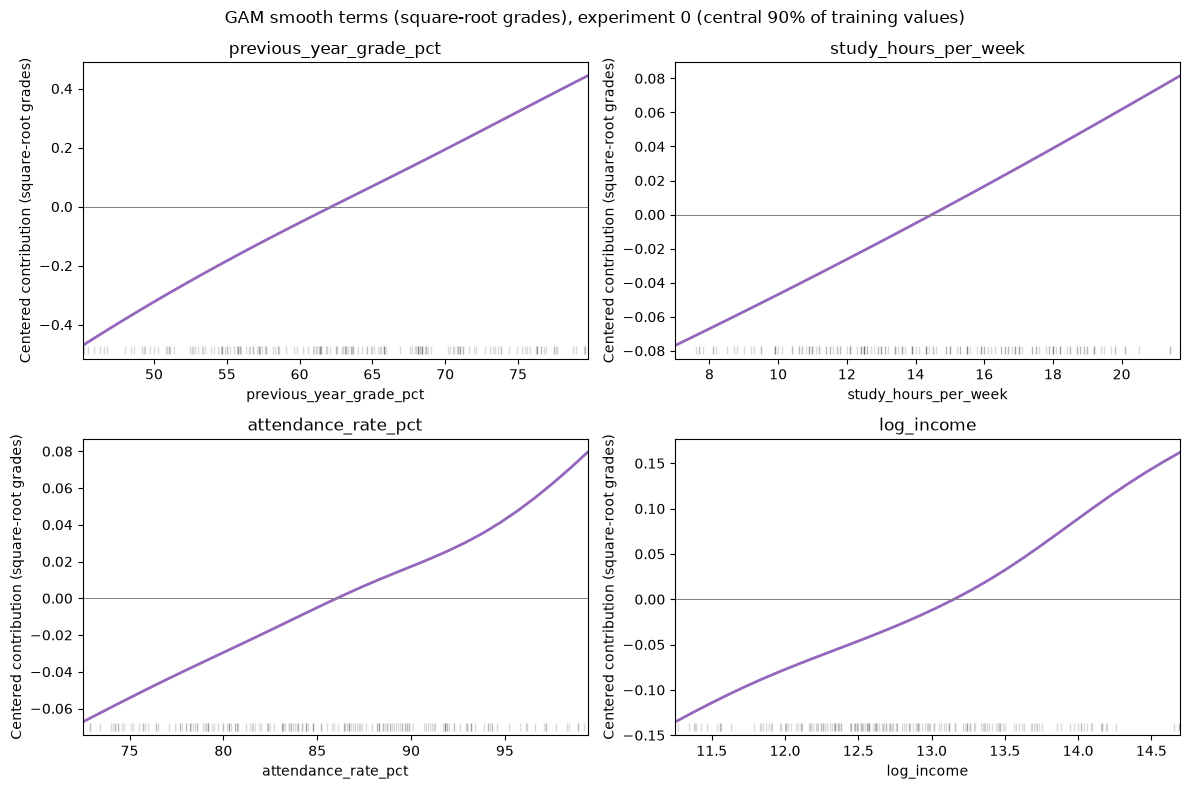

**GAM interpretation.** Each curve shows an additive contribution to the square-root target. Bends indicate nonlinear behavior learned by this fit; the rug shows training support. No inferential bands are shown because this plot does not account for tuning and split uncertainty.

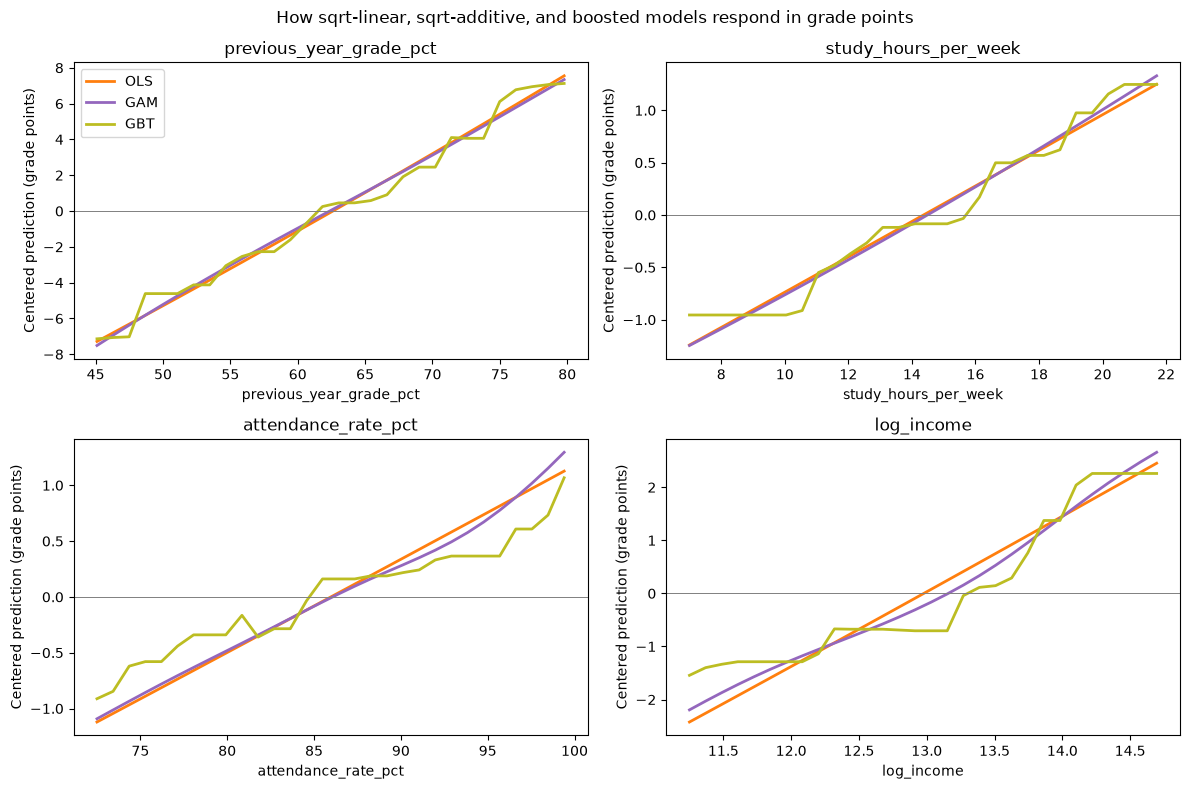

**Linear versus nonlinear response.** OLS is linear on the square-root scale; GAM permits smooth additive changes on that scale; inverse transformation makes both nonlinear in grade points. GBT can capture thresholds and interactions. Similar curves support a simpler description; differences motivate checking residuals and paired performance before preferring a more complex model.

In [26]:
effect_features = ['previous_year_grade_pct', 'study_hours_per_week', 'attendance_rate_pct', 'log_income']
explanation_train = regression_diagnostic_data['X_train']
gam_pipeline = regression_diagnostic_models['GAM']
gam_pipeline = gam_pipeline.regressor_ if hasattr(gam_pipeline, 'regressor_') else gam_pipeline
gam_prep = gam_pipeline.named_steps['prep']
gam = gam_pipeline.named_steps['model'].gam_
encoded_names = list(gam_prep.get_feature_names_out())
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, effect_features):
    feature_index = encoded_names.index('num__' + feature)
    values = explanation_train[feature].to_numpy()
    grid = np.linspace(*np.quantile(values, [.05, .95]), 30)
    design = np.tile(gam_prep.transform(explanation_train.iloc[:1]), (len(grid), 1))
    design[:, feature_index] = grid
    effect = gam.partial_dependence(term=feature_index, X=design)
    ax.plot(grid, effect - effect.mean(), color=MODEL_COLORS['GAM'], linewidth=2)
    rug = np.random.default_rng(0).choice(values, size=min(200, len(values)), replace=False)
    ax.plot(rug, np.full(len(rug), .03), '|', transform=ax.get_xaxis_transform(), alpha=.15, color='black')
    ax.set(xlim=(grid[0], grid[-1]), xlabel=feature, ylabel='Centered contribution (square-root grades)', title=feature)
    ax.axhline(0, color='grey', linewidth=.7)
fig.suptitle('GAM smooth terms (square-root grades), experiment 0 (central 90% of training values)')
plt.tight_layout()
plt.show()
explain("**GAM interpretation.** Each curve shows an additive contribution to the square-root target. Bends indicate "
        "nonlinear behavior learned by this fit; the rug shows training support. No inferential bands are shown "
        "because this plot does not account for tuning and split uncertainty.")

# Manual marginal averaging works with the existing custom GAM wrapper as well as sklearn models.
explanation_sample = explanation_train.sample(n=min(500, len(explanation_train)), random_state=0)
partial_dependence_records = []
response_names = ['OLS', 'GAM', 'GBT']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, effect_features):
    grid = np.linspace(*explanation_train[feature].quantile([.05, .95]).to_numpy(), 30)
    for name in response_names:
        model = regression_diagnostic_models[name]
        curve = []
        for value in grid:
            altered = explanation_sample.copy()
            altered[feature] = value
            curve.append(np.mean(model.predict(altered)))
        curve = np.asarray(curve)
        centered = curve - curve.mean()
        ax.plot(grid, centered, label=name, color=MODEL_COLORS[name], linewidth=2)
        partial_dependence_records.extend({'model': name, 'feature': feature, 'value': value, 'centered prediction': effect}
                                          for value, effect in zip(grid, centered))
    ax.set(xlabel=feature, ylabel='Centered prediction (grade points)', title=feature)
    ax.axhline(0, color='grey', linewidth=.7)
axes.flat[0].legend()
fig.suptitle('How sqrt-linear, sqrt-additive, and boosted models respond in grade points')
plt.tight_layout()
plt.show()
explain("**Linear versus nonlinear response.** OLS is linear on the square-root scale; GAM permits smooth additive "
        "changes on that scale; inverse transformation makes both nonlinear in grade points. GBT can capture thresholds and interactions. Similar curves support a simpler description; "
        "differences motivate checking residuals and paired performance before preferring a more complex model.")

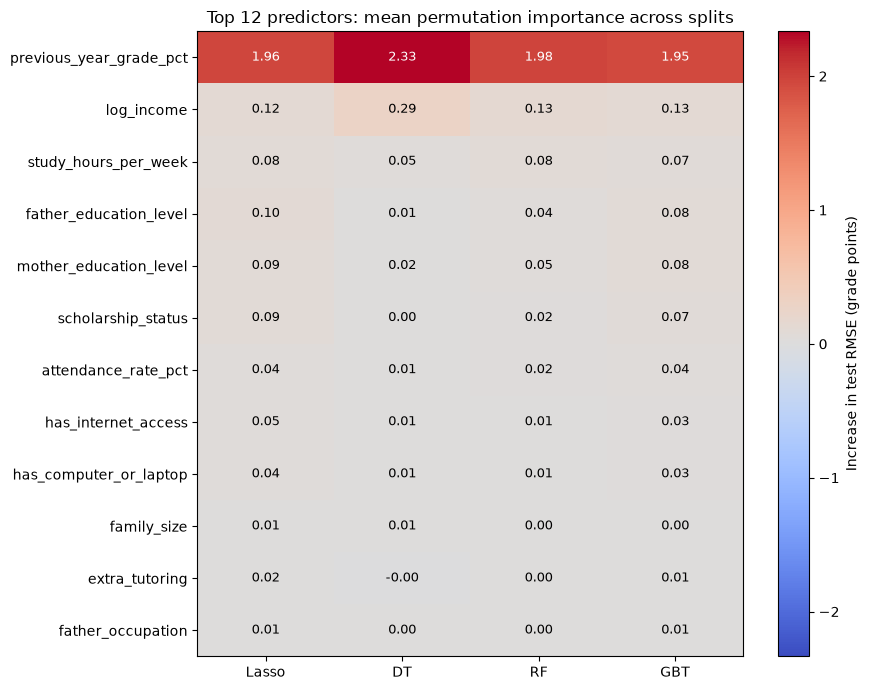

**Importance agreement.** Shared high-importance predictors suggest models rely on similar information. Values retain grade-point units, so this is reliance rather than a normalized rank. Correlated predictors can substitute for each other; near-zero or negative values need cautious interpretation. The existing feature-selection section also shows split-to-split spread.

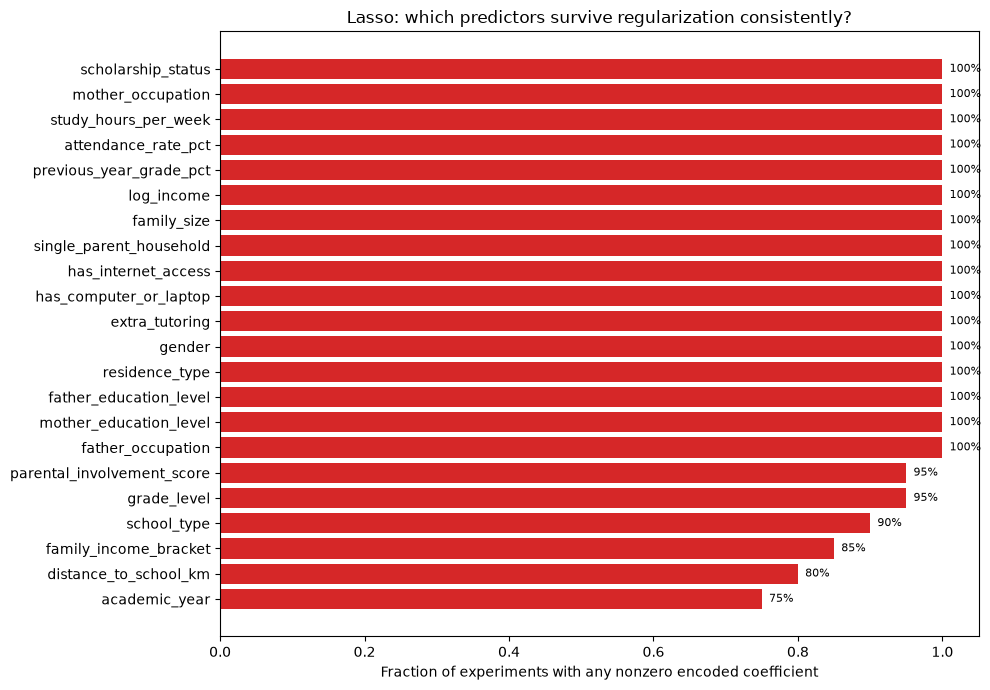

**Selection stability.** A categorical predictor is retained when any encoded level is nonzero. Stable selection does not establish causation or unique importance. Lasso numeric coefficients are square-root changes per training SD; ordinal coefficients are per encoded level; one-hot coefficients are relative to the omitted category. Their magnitudes are not on a common scale.

In [27]:
importance_frame = pd.DataFrame(importance_records)
importance_models = ['Lasso', 'DT', 'RF', 'GBT']
importance_means = importance_frame.groupby('model')[PREDICTOR_COLS].mean().reindex(importance_models).T
importance_features = importance_means.mean(axis=1).nlargest(12).index
importance_plot = importance_means.loc[importance_features]
limit = max(float(importance_plot.abs().max().max()), 1e-12)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(importance_plot, aspect='auto', cmap='coolwarm', vmin=-limit, vmax=limit)
ax.set_xticks(range(len(importance_models)), importance_models)
ax.set_yticks(range(len(importance_features)), importance_features)
for row in range(len(importance_features)):
    for col in range(len(importance_models)):
        value = importance_plot.iloc[row, col]
        ax.text(col, row, f'{value:.2f}', ha='center', va='center',
                color='white' if abs(value) > .6 * limit else 'black', fontsize=9)
ax.set_title('Top 12 predictors: mean permutation importance across splits')
fig.colorbar(image, ax=ax, label='Increase in test RMSE (grade points)')
plt.tight_layout()
plt.show()
explain("**Importance agreement.** Shared high-importance predictors suggest models rely on similar information. "
        "Values retain grade-point units, so this is reliance rather than a normalized rank. Correlated predictors "
        "can substitute for each other; near-zero or negative values need cautious interpretation. "
        "The existing feature-selection section also shows split-to-split spread.")

lasso_stability = pd.DataFrame(lasso_selection_records).drop(columns='experiment').mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(lasso_stability.index, lasso_stability, color=MODEL_COLORS['Lasso'])
ax.set(xlim=(0, 1.05), xlabel='Fraction of experiments with any nonzero encoded coefficient',
       title='Lasso: which predictors survive regularization consistently?')
for position, value in enumerate(lasso_stability):
    ax.text(value + .01, position, f'{value:.0%}', va='center', fontsize=8)
plt.tight_layout()
plt.show()
explain("**Selection stability.** A categorical predictor is retained when any encoded level is nonzero. "
        "Stable selection does not establish causation or unique importance. Lasso numeric coefficients are "
        "square-root changes per training SD; ordinal coefficients are per encoded level; one-hot coefficients are "
        "relative to the omitted category. Their magnitudes are not on a common scale.")

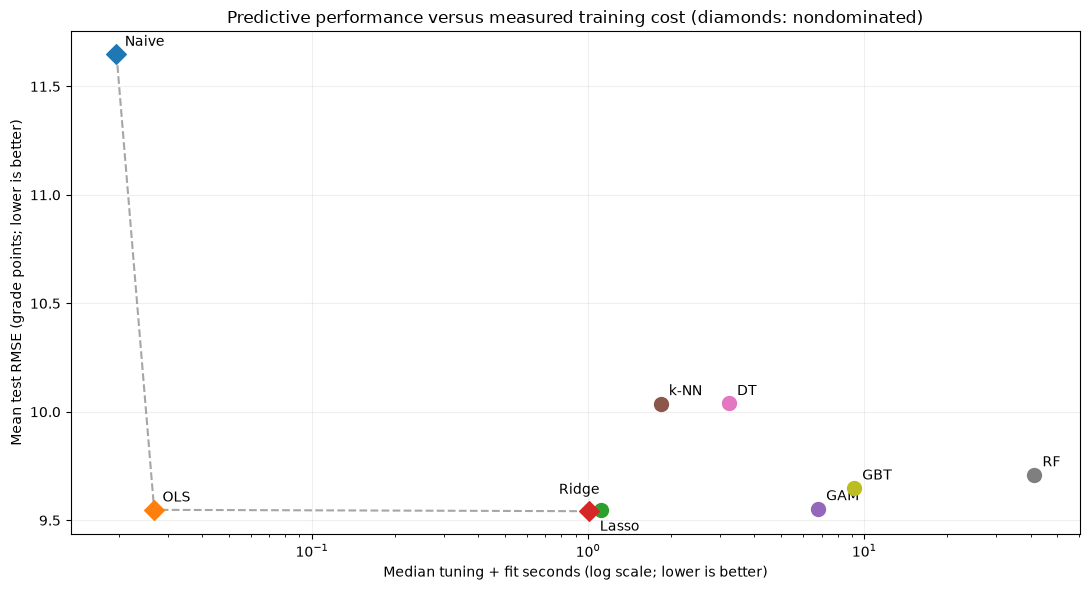

,mean test RMSE,median tuning + fit seconds,median prediction seconds,nondominated
model,,,,
Naive,11.6485,0.0196,0.0048,True
OLS,9.5481,0.0268,0.0050,True
Ridge,9.5453,1.1089,0.0051,False
Lasso,9.5419,1.0044,0.0051,True
GAM,9.5541,6.7848,0.0127,False
k-NN,10.0383,1.8275,0.0910,False
DT,10.0392,3.2275,0.0045,False
RF,9.7106,41.1780,0.0176,False
GBT,9.6495,9.1667,0.0086,False


**Computational tradeoff.** Diamonds identify models for which no alternative is both at least as fast and at least as accurate, with one strict improvement. These are empirical means and medians, not uncertainty-aware dominance claims. Timing includes each existing search budget and final refit; RF uses five CV folds while most tuned regressors use ten. Machine, parallelism, and grid size affect the comparison. Prediction timings cover one complete test batch and can be noisy.

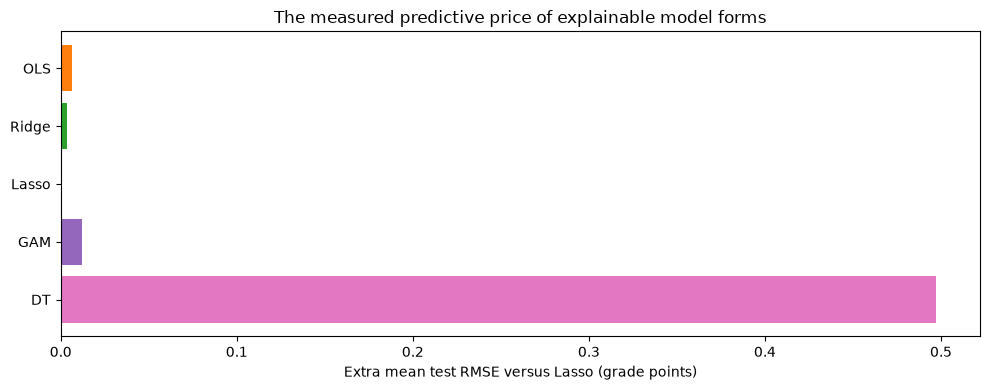

,extra RMSE (grade points),extra RMSE (%),explanation form
model,,,
OLS,0.006,0.066,Linear coefficients
Ridge,0.003,0.035,Regularized linear coefficients
Lasso,0.000,0.000,Sparse linear coefficients
GAM,0.012,0.128,Additive smooth curves
DT,0.497,5.212,Decision rules (readability depends on tree size)


**Interpretability price.** Among the listed model forms, Lasso has the smallest RMSE penalty (0.000 grade points) relative to Lasso. The reference was selected from these test results, so this penalty is descriptive. Interpretability depends on the audience and fitted complexity; no numerical interpretability score is assigned. Small gaps should be read alongside the paired intervals and residual plots.

In [28]:
runtime_summary = regression_timings.groupby('model')[['fit seconds', 'prediction seconds']].median().reindex(REGRESSION_NAMES)
tradeoff_summary = pd.DataFrame({
    'mean test RMSE': performance_summary[('RMSE', 'mean')],
    'median tuning + fit seconds': runtime_summary['fit seconds'],
    'median prediction seconds': runtime_summary['prediction seconds'],
})
costs = tradeoff_summary[['median tuning + fit seconds', 'mean test RMSE']].to_numpy()
tradeoff_summary['nondominated'] = [
    not any(np.all(other <= point) and np.any(other < point) for other in costs)
    for point in costs
]
fig, ax = plt.subplots(figsize=(11, 6))
for name, row in tradeoff_summary.iterrows():
    ax.scatter(max(row['median tuning + fit seconds'], 1e-9), row['mean test RMSE'],
               color=MODEL_COLORS[name], s=100,
               marker='D' if row['nondominated'] else 'o', zorder=3)
    ax.annotate(name, (max(row['median tuning + fit seconds'], 1e-9), row['mean test RMSE']),
                xytext={'Ridge': (-30, 12), 'Lasso': (8, -14)}.get(name, (6, 6)),
                textcoords='offset points')
frontier = tradeoff_summary[tradeoff_summary['nondominated']].sort_values('median tuning + fit seconds')
ax.plot(frontier['median tuning + fit seconds'].clip(lower=1e-9), frontier['mean test RMSE'],
        linestyle='--', color='grey', alpha=.7)
ax.set_xscale('log')
ax.set(xlabel='Median tuning + fit seconds (log scale; lower is better)',
       ylabel='Mean test RMSE (grade points; lower is better)',
       title='Predictive performance versus measured training cost (diamonds: nondominated)')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
display(tradeoff_summary.round(4))
explain("**Computational tradeoff.** Diamonds identify models for which no alternative is both at least as fast "
        "and at least as accurate, with one strict improvement. These are empirical means and medians, not "
        "uncertainty-aware dominance claims. Timing includes each existing search budget and final refit; "
        "RF uses five CV folds while most tuned regressors use ten. Machine, parallelism, and grid size affect "
        "the comparison. Prediction timings cover one complete test batch and can be noisy.")

interpretable_names = ['OLS', 'Ridge', 'Lasso', 'GAM', 'DT']
best_rmse = performance_summary.loc[best_rmse_model, ('RMSE', 'mean')]
interpretability_cost = pd.DataFrame({
    'extra RMSE (grade points)': performance_summary.loc[interpretable_names, ('RMSE', 'mean')] - best_rmse,
})
interpretability_cost['extra RMSE (%)'] = (
    100 * interpretability_cost['extra RMSE (grade points)'] / best_rmse if best_rmse > 0 else np.nan)
interpretability_cost['explanation form'] = [
    'Linear coefficients', 'Regularized linear coefficients', 'Sparse linear coefficients',
    'Additive smooth curves', 'Decision rules (readability depends on tree size)',
]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(interpretability_cost.index, interpretability_cost['extra RMSE (grade points)'],
        color=[MODEL_COLORS[m] for m in interpretable_names])
ax.set(xlabel=f'Extra mean test RMSE versus {best_rmse_model} (grade points)',
       title='The measured predictive price of explainable model forms')
ax.invert_yaxis()
plt.tight_layout()
plt.show()
display(interpretability_cost.round(3))
lowest_penalty = interpretability_cost['extra RMSE (grade points)'].idxmin()
explain(f"**Interpretability price.** Among the listed model forms, {lowest_penalty} has the smallest RMSE "
        f"penalty ({interpretability_cost.loc[lowest_penalty, 'extra RMSE (grade points)']:.3f} grade points) "
        f"relative to {best_rmse_model}. The reference was selected from these test results, so this penalty "
        "is descriptive. Interpretability depends on the audience and fitted complexity; no numerical "
        "interpretability score is assigned. Small gaps should be read alongside the paired intervals and residual plots.")

In [29]:
coefficients = pd.DataFrame([{k:v for k,v in p.items() if k not in ['experiment','condition','model']}
    for r in results for p in r['coefficients'] if p['condition']==condition])
coefficient_summary = pd.DataFrame({'mean coefficient':coefficients.mean(), 'split SD':coefficients.std()})
display(coefficient_summary.reindex(coefficient_summary['mean coefficient'].abs().nlargest(15).index).round(3))
print('Coefficient units:', 'square-root grades' if condition=='Sqrt' else 'grade points')

,mean coefficient,split SD
num__previous_year_grade_pct,0.275,0.002
ordinal__scholarship_status,0.089,0.005
num__log_income,0.064,0.006
onehot__father_occupation_Unemployed,0.057,0.007
num__study_hours_per_week,0.051,0.004
num__has_internet_access,0.042,0.003
num__attendance_rate_pct,0.039,0.003
num__has_computer_or_laptop,0.039,0.003
ordinal__father_education_level,0.039,0.002
ordinal__mother_education_level,0.037,0.003


Coefficient units: square-root grades


## Optional unsupervised analysis

Retained from the original notebook; this section is separate from the paired regression experiment.

# Unsupervised Learning: K-means and PCA (AI Slop)

Feature Exploration 
Dimensionality Reduction (PCA) / Clustering (K-means)

The setup below uses the shared predictors only. Numeric variables are standardized, ordinal variables keep their existing order, and all one-hot levels are retained so categories have equal pairwise distances. The encoded categorical variables are not standardized, so their weights differ from those of the numeric variables. This is exploratory preprocessing fitted on all available rows; predictive use would require fitting it on training data only.

PCA summarises variation in the prepared predictors. The first two components may not capture all of the structure in the data, and large loadings do not necessarily imply predictive importance.

K-means is fitted on all prepared predictors, not just the first two principal components. Silhouette scores use the same random sample of up to 2,000 students for each candidate. The highest score gives a provisional choice of cluster count; check the scores, sizes, stability and profiles before interpreting it. The seed comparison checks sensitivity to initialization, not sampling or preprocessing choices.

The PCA plots show the same two-dimensional projection coloured by cluster and by grade class. Clusters are fitted in the full predictor space, and grades are added only afterwards. Differences between groups are descriptive associations, not causal effects or independent validation; the clusters may change with the choice of preprocessing and distance weights.


In [ ]:
# Setup for PCA and K-means
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

UNSUPERVISED_RANDOM_STATE = 0
CLUSTER_COUNTS            = range(2, 9)

# Keep all one-hot levels for distances; scale numeric columns only
unsupervised_prep = ColumnTransformer([
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ONEHOT_COLUMNS),
    ('ordinal', OrdinalEncoder(categories=list(ORDINAL_COLUMNS.values())), list(ORDINAL_COLUMNS)),
    ('numeric', StandardScaler(), NUMERIC_COLS),
])

unsupervised_values = unsupervised_prep.fit_transform(X)
X_unsupervised = pd.DataFrame(
    unsupervised_values,
    index=X.index,
    columns=unsupervised_prep.get_feature_names_out()
)

# Define PCA and candidate K-means models
pca_model = PCA()
kmeans_models = {
    count: KMeans(n_clusters=count, n_init=10, random_state=UNSUPERVISED_RANDOM_STATE)
    for count in CLUSTER_COUNTS
}

# Fit PCA and inspect explained variance and loadings
from IPython.display import display

pca_scores = pca_model.fit_transform(X_unsupervised)
explained_variance = pca_model.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
components_for_80_percent = np.searchsorted(cumulative_variance, 0.80) + 1

print(f'Components needed for 80% of variance: {components_for_80_percent}')

pca_loadings = pd.DataFrame(
    pca_model.components_[:2].T,
    index=X_unsupervised.columns,
    columns=['PC1', 'PC2']
)
for component in pca_loadings.columns:
    largest_loadings = pca_loadings[component].abs().nlargest(5).index
    print(f'Largest {component} loadings:')
    display(pca_loadings.loc[largest_loadings, [component]].round(3))

# Compare cluster counts using inertia and silhouette score
from sklearn.metrics import adjusted_rand_score, silhouette_score

cluster_results = []
for count, model in kmeans_models.items():
    labels = model.fit_predict(X_unsupervised)
    cluster_results.append({
        'clusters':   count,
        'inertia':    model.inertia_,
        'silhouette': silhouette_score(
            X_unsupervised, labels, sample_size=min(2000, len(X_unsupervised)),
            random_state=UNSUPERVISED_RANDOM_STATE
        ),
    })

cluster_results = pd.DataFrame(cluster_results).set_index('clusters')
display(cluster_results.round(3))

selected_cluster_count = cluster_results['silhouette'].idxmax()
selected_kmeans = kmeans_models[selected_cluster_count]
cluster_labels = pd.Series(selected_kmeans.labels_ + 1, index=X.index, name='cluster')
print(f'Provisional cluster count: {selected_cluster_count}')

# Compare the selected solution with other random initializations
seed_stability = []
for seed in [1, 2, 3]:
    alternative_model = KMeans(n_clusters=selected_cluster_count, n_init=10, random_state=seed)
    alternative_labels = alternative_model.fit_predict(X_unsupervised)
    seed_stability.append({
        'random_state': seed,
        'adjusted_rand_score': adjusted_rand_score(selected_kmeans.labels_, alternative_labels)
    })
print('Agreement with the selected solution across random seeds:')
display(pd.DataFrame(seed_stability).set_index('random_state').round(3))

# Summarise predictors and grades after assigning clusters
profile_columns = [
    'study_hours_per_week', 'attendance_rate_pct',
    'previous_year_grade_pct', 'log_income'
]
cluster_data = X[profile_columns].copy()
cluster_data['cluster'] = cluster_labels
cluster_data['final_grade_pct'] = Y_regression
cluster_data['grade_class'] = Y_classification

cluster_profile = cluster_data.groupby('cluster')[profile_columns + ['final_grade_pct']].mean()
cluster_profile.insert(0, 'students', cluster_labels.value_counts().sort_index())
overall_profile = pd.DataFrame(
    [[len(cluster_data)] + cluster_data[profile_columns + ['final_grade_pct']].mean().tolist()],
    index=['Overall'], columns=cluster_profile.columns
)
print('Cluster means and overall means:')
display(pd.concat([cluster_profile, overall_profile]).round(2))

grade_distribution = pd.crosstab(cluster_labels, Y_classification, normalize='index')
print('Grade class distribution within each cluster:')
display((100 * grade_distribution).round(1))
print('School type distribution within each cluster (%):')
display((100 * pd.crosstab(cluster_labels, X['school_type'], normalize='index')).round(1))


## Unsupervised Learning: Visualisation

In [ ]:
# PCA explained variance
component_numbers = np.arange(1, len(explained_variance) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(component_numbers, explained_variance)
axes[0].set(title='PCA explained variance', xlabel='Principal component', ylabel='Variance explained')
axes[1].plot(component_numbers, cumulative_variance, marker='o', markersize=3)
axes[1].axhline(0.80, color='grey', linestyle='--', label='80%')
axes[1].set(title='Cumulative explained variance', xlabel='Number of components', ylabel='Cumulative variance')
axes[1].legend()
plt.tight_layout()
plt.show()

# Largest signed loadings for the first two principal components
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, component in zip(axes, ['PC1', 'PC2']):
    largest_features = pca_loadings[component].abs().nlargest(5).index
    loadings = pca_loadings.loc[largest_features, component].sort_values()
    ax.barh(loadings.index, loadings.values)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set(title=f'{component}: largest loadings', xlabel='Loading')
plt.tight_layout()
plt.show()

# K-means diagnostics
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cluster_results.index, cluster_results['inertia'], marker='o')
axes[0].set(title='K-means inertia', xlabel='Number of clusters', ylabel='Inertia')
axes[1].plot(cluster_results.index, cluster_results['silhouette'], marker='o')
axes[1].set(title='K-means silhouette score', xlabel='Number of clusters', ylabel='Silhouette score')
plt.tight_layout()
plt.show()

# Compare clusters and grade classes on the same PCA projection
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for cluster in sorted(cluster_labels.unique()):
    in_cluster = cluster_labels.to_numpy() == cluster
    axes[0].scatter(pca_scores[in_cluster, 0], pca_scores[in_cluster, 1],
                    s=10, alpha=0.35, label=f'Cluster {cluster}')

grade_classes = Y_classification.reindex(X_unsupervised.index)
for grade in grade_classes.value_counts().index:
    in_grade = grade_classes.to_numpy() == grade
    axes[1].scatter(pca_scores[in_grade, 0], pca_scores[in_grade, 1],
                    s=10, alpha=0.35, label=f'Grade {grade}')

for ax in axes:
    ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%} variance)')
    ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%} variance)')
    ax.legend()
axes[0].set_title('Coloured by cluster')
axes[1].set_title('Coloured by grade class')
plt.tight_layout()
plt.show()

# Grade class distribution within each cluster
grade_distribution.plot.bar(stacked=True, figsize=(8, 5), colormap='viridis')
plt.title('Grade class distribution by cluster')
plt.xlabel('Cluster')
plt.ylabel('Proportion of students')
plt.legend(title='Grade class', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
